# SMDA Final Project

## 0. load dependencies and packages

In [431]:
import pandas as pd
import matplotlib.pyplot as plt
from pytrends.request import TrendReq
import requests
import time
from thefuzz import process, fuzz
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
import statsmodels.api as sm

## 1. Data retrieval & Preprocessing

### 1.1 Google Trends Data on divers issue salient topics

We retrieve data of google trends topics and check their related queries to verify Content Validity. 

In [664]:
import requests

session = requests.Session()
session.get('https://trends.google.com')
cookies_map = session.cookies.get_dict()
nid_cookie = cookies_map['NID']

pytrends = TrendReq(hl='de-DE', tz=60, requests_args={'headers': {'Cookie': f'NID={nid_cookie}'}})

In [665]:
pytrends.build_payload(kw_list=['/g/121jc7sl'], timeframe='today 5-y', geo='DE', gprop='')
immigration = pytrends.interest_over_time()

related = pytrends.related_queries()

related['/g/121jc7sl']['top']

/opt/miniconda3/lib/python3.12/site-packages/pytrends/request.py:260: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.fillna(False)


,query,value
0,migration,100
1,migranten,41
2,deutschland migration,7
3,migranten deutschland,7
4,flüchtlinge,7
5,migrant,6
6,migrants,5
7,integration,5
8,migranten in deutschland,4
9,definition migration,3


In [203]:
pytrends.build_payload(kw_list=['/m/0d063v'], timeframe='today 5-y', geo='DE', gprop='')
climate_change = pytrends.interest_over_time()

related = pytrends.related_queries()

related['/m/0d063v']['top'].head()

/opt/miniconda3/lib/python3.12/site-packages/pytrends/request.py:260: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.fillna(False)


,query,value
0,klimawandel,100
1,climate change,33
2,global warming,6
3,klima,5
4,klimawandel deutschland,5


In [204]:
pytrends.build_payload(kw_list=['/m/04jg4rw'], timeframe='today 5-y', geo='DE', gprop='')
military_policy = pytrends.interest_over_time()

related = pytrends.related_queries()

related['/m/04jg4rw']['top'].head()

/opt/miniconda3/lib/python3.12/site-packages/pytrends/request.py:260: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.fillna(False)


,query,value
0,sicherheitspolitik,100
1,eu,12
2,sicherheitspolitik eu,10
3,außen und sicherheitspolitik,9
4,bundeswehr,6


In [ ]:
pytrends.build_payload(kw_list=['/m/03h76d'], timeframe='today 5-y', geo='DE', gprop='')
social_policy = pytrends.interest_over_time()

related = pytrends.related_queries()

related['/m/03h76d']['top'].head()

In [210]:
pytrends.build_payload(kw_list=['/m/012_3l'], timeframe='today 5-y', geo='DE', gprop='')
economic_growth = pytrends.interest_over_time()

related = pytrends.related_queries()

related['/m/012_3l']['top'].head()

/opt/miniconda3/lib/python3.12/site-packages/pytrends/request.py:260: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.fillna(False)


,query,value
0,wirtschaftswachstum,100
1,gdp,15
2,economic growth,15
3,gdp growth,14
4,bip,10


In [212]:
pytrends.build_payload(kw_list=['/m/09jx2'], timeframe='today 5-y', geo='DE', gprop='')
inflation = pytrends.interest_over_time()

related = pytrends.related_queries()

related['/m/09jx2']['top'].head()

/opt/miniconda3/lib/python3.12/site-packages/pytrends/request.py:260: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.fillna(False)


,query,value
0,inflation,100
1,inflation deutschland,22
2,inflationsrate,17
3,inflation 2022,7
4,deutschland inflationsrate,6


In [ ]:
topics = [immigration, climate_change, military_policy, social_policy, economic_growth, inflation]
topic_names = ['immigration', 'climate_change', 'military_policy', 'social_policy', 'econonmic_growth', 'inflation']

processed_topics = []

for topic, name in zip(topics, topic_names): 
    df = topic.iloc[:, :1].rename(columns={topic.columns[0]: name})
    processed_topics.append(df)

topic_df = pd.concat(processed_topics, axis=1)
topic_df = processed_topics[0].join(processed_topics[1:])
topic_df.reset_index(inplace=True)

#getting week and year for matching with other data 
topic_df['date'] = pd.to_datetime(topic_df['date'])
topic_df['week'] = topic_df['date'].dt.isocalendar().week
topic_df['year'] = topic_df['date'].dt.isocalendar().year
topic_df.to_csv('google_topics.csv', index=False)  

In [724]:
topic_df = pd.read_csv('google_topics.csv')
topic_df['date'] = pd.to_datetime(topic_df['date'])
topic_df['month'] = topic_df['date'].dt.month
topic_df.head()

,date,immigration,climate_change,military_policy,social_policy,econonmic_growth,inflation,week,year,month
0,2020-09-13,18,1,23,66,49,16,37,2020,9
1,2020-09-20,18,1,26,66,47,16,38,2020,9
2,2020-09-27,16,1,21,70,47,17,39,2020,9
3,2020-10-04,13,1,24,65,47,15,40,2020,10
4,2020-10-11,13,1,0,54,39,16,41,2020,10


In [726]:
topic_df['date'].min()

Timestamp('2020-09-13 00:00:00')

### 1.2 Google Trends data on immigration related search terms

In [227]:
session = requests.Session()
session.get('https://trends.google.com')
cookies_map = session.cookies.get_dict()
nid_cookie = cookies_map['NID']

pytrends = TrendReq(hl='de-DE', tz=60, requests_args={'headers': {'Cookie': f'NID={nid_cookie}'}})

In [ ]:
pytrends.build_payload(kw_list=['Immigration'], timeframe='today 5-y', geo='DE', gprop='')
immigration = pytrends.interest_over_time()

related = pytrends.related_queries()

related['Immigration']['top']

/opt/miniconda3/lib/python3.12/site-packages/pytrends/request.py:260: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.fillna(False)


,query,value
0,immigration office,100
1,usa immigration,81
2,us immigration,72
3,canada immigration,64
4,canada,63


In [232]:
pytrends.build_payload(kw_list=['Flüchtlinge'], timeframe='today 5-y', geo='DE', gprop='')
fluechtlinge = pytrends.interest_over_time()

related = pytrends.related_queries()

related['Flüchtlinge']['top']

/opt/miniconda3/lib/python3.12/site-packages/pytrends/request.py:260: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.fillna(False)


,query,value
0,ukraine flüchtlinge,100
1,ukrainische flüchtlinge,63
2,flüchtlinge in deutschland,35
3,migration,24
4,flüchtlinge news,18
5,bundesamt für migration und flüchtlinge,17
6,migranten,9
7,flüchtlinge 2015,6
8,8000 flüchtlinge griechenland,2


In [234]:
pytrends.build_payload(kw_list=['Migration'], timeframe='today 5-y', geo='DE', gprop='')
migration = pytrends.interest_over_time()

related = pytrends.related_queries()

related['Migration']['top']

/opt/miniconda3/lib/python3.12/site-packages/pytrends/request.py:260: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.fillna(False)


,query,value
0,flüchtlinge,100
1,deutschland migration,91
2,bundesamt migration,87
3,bundesamt für migration,85
4,bundesamt für migration und flüchtlinge,71
5,amt für migration,58
6,integration,56
7,data migration,49
8,migration und integration,39
9,definition migration,38


In [236]:
pytrends.build_payload(kw_list=['Einwanderung'], timeframe='today 5-y', geo='DE', gprop='')
einwanderung = pytrends.interest_over_time()

related = pytrends.related_queries()

related['Einwanderung']['top']

/opt/miniconda3/lib/python3.12/site-packages/pytrends/request.py:260: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.fillna(False)


,query,value
0,landesamt für einwanderung,100
1,einwanderung nach deutschland,16
2,einwanderung in deutschland,15
3,kanada,14
4,schweiz,10
5,einwanderung schweiz,10
6,migration,10
7,illegale einwanderung,10
8,einwanderung neuseeland,9
9,neuseeland,9


In [237]:
pytrends.build_payload(kw_list=['Asyl'], timeframe='today 5-y', geo='DE', gprop='')
asyl = pytrends.interest_over_time()

related = pytrends.related_queries()

related['Asyl']['top']

/opt/miniconda3/lib/python3.12/site-packages/pytrends/request.py:260: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.fillna(False)


,query,value
0,asyl deutschland,100
1,pro asyl,82
2,asyl in deutschland,53
3,flüchtlinge,48
4,asyl beantragen,47
5,migration,24
6,was ist asyl,22
7,asyl ukraine,20
8,asylbewerber,17
9,unterkunft asyl,14


In [238]:
pytrends.build_payload(kw_list=['Zuwanderung'], timeframe='today 5-y', geo='DE', gprop='')
zuwanderung = pytrends.interest_over_time()

related = pytrends.related_queries()

related['Zuwanderung']['top']

/opt/miniconda3/lib/python3.12/site-packages/pytrends/request.py:260: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.fillna(False)


,query,value
0,deutschland zuwanderung,100
1,zuwanderung in deutschland,25
2,migration,20
3,zuwanderung nach deutschland,19
4,flüchtlinge,18
5,migration deutschland,9
6,zuwanderung deutschland 2023,8
7,landesamt für zuwanderung und flüchtlinge,8
8,afd zuwanderung,7
9,helmut schmidt zuwanderung,6


In [240]:
terms_dfs = [immigration, fluechtlinge, migration, einwanderung, asyl, zuwanderung]
terms = ['immigration', 'fluechtlinge', 'migration', 'einwanderung', 'asyl', 'zuwanderung']

processed_terms = []

for topic, name in zip(terms_dfs, terms): 
    df = topic.iloc[:, :1].rename(columns={topic.columns[0]: name})
    processed_terms.append(df)

term_df = pd.concat(processed_terms, axis=1)
term_df = processed_terms[0].join(processed_terms[1:])
term_df.reset_index(inplace=True)

#getting week and year for matching with other data 
term_df['date'] = pd.to_datetime(term_df['date'])
term_df['week'] = term_df['date'].dt.isocalendar().week
term_df['year'] = term_df['date'].dt.isocalendar().year
term_df.to_csv('immigration_term.csv', index=False) 
term_df.head()

,date,immigration,fluechtlinge,migration,einwanderung,asyl,zuwanderung,week,year
0,2020-09-13,53,22,17,26,18,23,37,2020
1,2020-09-20,53,12,20,35,22,26,38,2020
2,2020-09-27,52,9,16,31,18,21,39,2020
3,2020-10-04,43,8,15,25,17,15,40,2020
4,2020-10-11,39,8,15,24,17,19,41,2020


In [391]:
term_df = pd.read_csv('immigration_term.csv')
term_df['date'] = pd.to_datetime(term_df['date'])
term_df['month'] = term_df['date'].dt.month
term_df.head()

,date,immigration,fluechtlinge,migration,einwanderung,asyl,zuwanderung,week,year,month
0,2020-09-13,53,22,17,26,18,23,37,2020,9
1,2020-09-20,53,12,20,35,22,26,38,2020,9
2,2020-09-27,52,9,16,31,18,21,39,2020,9
3,2020-10-04,43,8,15,25,17,15,40,2020,10
4,2020-10-11,39,8,15,24,17,19,41,2020,10


### 1.3 Weekly Polling Data by FORSA

In [402]:
# get polling from forsa

url = 'https://www.wahlrecht.de/umfragen/forsa.htm'
tables = pd.read_html(url)


#preprocessing 
df = tables[1]
df = df.iloc[:624].copy()
df['date'] = pd.to_datetime(df['Unnamed: 0'], dayfirst=True) 
df['week'] = df['date'].dt.isocalendar().week
df['year'] = df['date'].dt.isocalendar().year

#same time frame 
df = df[(df['date']>= min(topic_df['date'])) & (df['date']<= max(topic_df['date']))]
df = df[['date','week', 'year','CDU/CSU','SPD','GRÜNE','FDP','LINKE','AfD','BSW','Sonstige','Nichtwähler/ Unentschl.','Befragte']]

#actual election data is also in there, we cut it
df = df[df['Befragte']!='Bundestag']

#strings to integers 
columns = ['CDU/CSU','SPD','GRÜNE','FDP','LINKE','AfD','BSW','Sonstige','Nichtwähler/ Unentschl.']
for col in columns:
    df[col] = df[col].str.replace('%', '').str.replace(',', '.').str.strip()
    df[col] = pd.to_numeric(df[col], errors='coerce')

#averaging polling results for two values per week and year
polling_df = df.groupby(['year', 'week'])[['CDU/CSU', 'SPD','GRÜNE','FDP','LINKE','AfD','BSW','Sonstige','Nichtwähler/ Unentschl.']].mean().round(1).reset_index().copy()
polling_df

,year,week,CDU/CSU,SPD,GRÜNE,FDP,LINKE,AfD,BSW,Sonstige,Nichtwähler/ Unentschl.
0,2020,38,36.0,14.0,22.0,5.0,8.0,8.0,NaN,7.0,22.0
1,2020,39,35.0,15.0,21.0,6.0,8.0,9.0,NaN,6.0,23.0
2,2020,40,36.0,15.0,20.0,6.0,7.0,9.0,NaN,7.0,22.0
3,2020,41,36.0,15.0,20.0,5.0,8.0,9.0,NaN,7.0,21.0
4,2020,42,36.0,15.0,20.0,6.0,7.0,9.0,NaN,7.0,23.0
...,...,...,...,...,...,...,...,...,...,...,...
245,2025,33,24.0,13.0,13.0,3.0,11.0,26.0,4.0,6.0,25.0
246,2025,34,25.0,13.0,12.0,3.0,12.0,26.0,3.0,6.0,NaN
247,2025,35,25.0,13.0,12.0,3.0,11.0,26.0,3.0,7.0,26.0
248,2025,36,25.0,14.0,11.0,3.0,12.0,26.0,3.0,7.0,25.0


### 1.4 Politbarometer data for validation

Notes on preprocessing: All datasets have slight variation in variable names and exact wording leading to different preprocessing per dataset
addtionally to make the "most important question" comparable over many years, similiar entries had to be matched for our topics of interest

In [393]:
df_2020 = pd.read_spss("data/MIP_questions/politbarometer_2020.sav")  
df_2020['year'] = 2020
df_2020 = df_2020[['year','V5','V9','V10', 'V11','V12']]

df_2020.columns = ['year', 'week','mip','mip_2','wants_vote','vote']

#extract week for matching
df_2020["week"] = df_2020["week"].str.strip().str.split(".").str[0].astype(int)
df_2020["vote"] = df_2020["vote"].str.strip().str.split().str[1]

In [394]:
df_2021 = pd.read_spss("data/MIP_questions/politbarometer_2021.sav")  
df_2021['year'] = 2021
df_2021 = df_2021[['year','V5','V9','V10', 'V11','V14']]

df_2021.columns = ['year', 'week','mip','mip_2','wants_vote','vote']

#extract week for matching
df_2021["week"] = df_2021["week"].str.strip().str.split(".").str[0].astype(int)
df_2021["vote"] = df_2021["vote"].str.strip().str.split().str[1]

In [395]:
df_2022 = pd.read_spss("data/MIP_questions/politbarometer_2022.sav")  
df_2022['year'] = 2022
df_2022 = df_2022[['year','V5','V9','V10','V11','V12']]

df_2022.columns = ['year', 'week','mip','mip_2','wants_vote','vote']

#extract week for matching
df_2022["week"] = df_2022["week"].str.strip().str.split(".").str[0].astype(int)
df_2022["vote"] = df_2022["vote"].str.strip().str.split().str[1]

In [396]:
df_2023 = pd.read_spss("data/MIP_questions/politbarometer_2023.sav")  
df_2023['year'] = 2023
df_2023 = df_2023[['year','intweek','v4','v5', 'v6','v7']]

df_2023.columns = ['year', 'week','mip','mip_2','wants_vote','vote']

df_2023["week"] = df_2023["week"].str.strip().str.split('-').str[1]
df_2023["week"] = df_2023["week"].str.strip().str.slice().str[1].astype(int)

In [397]:
df_2024 = pd.read_spss("data/MIP_questions/politbarometer_2024.sav")  

df_2024['year'] = 2024
df_2024 = df_2024[['year','intweek','v4','v5', 'v6','v7']]

df_2024.columns = ['year', 'week','mip','mip_2','wants_vote','vote']

df_2024["week"] = df_2024["week"].str.strip().str.slice().str[1].astype(int)

In [398]:
dfs = [df_2021, df_2022,df_2023, df_2024]

mip_df = df_2020.copy()
for i in dfs:
    mip_df = pd.concat([mip_df, i], ignore_index=True)

mip_df

,year,week,mip,mip_2,wants_vote,vote
0,2020,3,Ausländer/ Zuwanderung/ Integration/ Asyl/Flüc...,"soziales Gefälle/ Gerechtigkeit/ arm-reich/ ""U...",ja,SPD
1,2020,3,Gesundheitswesen/ Gesundheitspolitik/ Pflegeve...,Schule/ Bildung/ PISA,ja,CDU/CSU
2,2020,3,Ausländer/ Zuwanderung/ Integration/ Asyl/Flüc...,Steuern/ Steuererhöhungen/Steuerhinterziehung,ja,FDP
3,2020,3,Familie/ Kinder/ Jugend,"soziales Gefälle/ Gerechtigkeit/ arm-reich/ ""U...",ja,SPD
4,2020,3,Sonstige Probleme,NaN,ja,CDU/CSU
...,...,...,...,...,...,...
143309,2024,5,Umweltschutz/ Klimawandel/ Artenschutz,soziales Gefälle/ Gerechtigkeit/ arm-reich,ja,Grüne
143310,2024,5,Sozialleistungen/ Hartz IV/ Bürgergeld,(fehlender) Zusammenhalt in der Gesellschaft/ ...,ja,SPD
143311,2024,5,Wirtschaftslage,Zustand/ Streit in der Bundesregierung/Neuwahl,ja,CDU bzw. CSU
143312,2024,5,Flüchtlinge/ Ausländer/ Zuwanderung/ Integrati...,Wirtschaftslage,ja,FDP


In [399]:
# strip of unceccary backslashes whitespaced and then join togehter all words in regular intervalls
mip_df["mip"] = mip_df["mip"].fillna("").str.strip().str.split('/')
mip_df["mip"] = mip_df["mip"].apply(lambda l: " ".join(l))
mip_df["mip"] = (mip_df["mip"].str.replace(r"\s+", " ", regex=True).str.strip())

mip_df["mip_2"] = mip_df["mip_2"].fillna("").str.strip().str.split('/')
mip_df["mip_2"] = mip_df["mip_2"].apply(lambda l: " ".join(l))
mip_df["mip_2"] = (mip_df["mip_2"].str.replace(r"\s+", " ", regex=True).str.strip())

In [400]:
#copying strings of interest for google topics from mip_df['mip']value.counts() output and adjusting for clarity
#they gonna be match targets for similiarity score calculation
mip_df["mip"] = mip_df["mip"].str.replace(r"Coronavirus.*", "Coronavirus", regex=True)
topics = [
    #'Coronavirus',
    #topic climate change
    'Umweltschutz Klimawandel Artenschutz',
    'Energiewende erneuerbare Energien CO2-Steuer Kohleausstieg',
    #topic immigration
    'Ausländer Zuwanderung Integration Asyl',
    #topic economy
    'Wirtschaftslage',
    'Lebenshaltungskosten Preise Inflation',
    #topic military policy
    'Krieg Ukraine Kriegsangst Russland Putin',
    'Frieden Entspannung',
    #topic social policy
    'soziales Gefälle Gerechtigkeit']


# Different years use different wording for the same topic. 
# using fuzzy matchin module we can define one wording for the specific topics
#https://www.datacamp.com/tutorial/fuzzy-string-python
def matching(x, topics, threshold=70):
    if not x or x.strip() == "":
        return x
    matches = process.extract(x, topics, scorer=fuzz.token_sort_ratio) #this scorer ignores word order
#process extract gets similiarity score for all
#but some are not that similiar with our variables of interest, therefore we filter by a threshold
#and get first instance which is always highest match
    matches_filtered = [m for m in matches if m[1] >= threshold]
    if matches_filtered:
        return matches_filtered[0][0]
    else:
        return x

mip_df["mip_matched"] = mip_df["mip"].apply(lambda x: matching(x, topics))
mip_df["mip_2_matched"] = mip_df["mip_2"].apply(lambda x: matching(x, topics))

In [355]:
matched_topics = [f"mip_matched_{i}" for i in topics]
matched_topics

['mip_matched_Umweltschutz Klimawandel Artenschutz',
 'mip_matched_Energiewende erneuerbare Energien CO2-Steuer Kohleausstieg',
 'mip_matched_Ausländer Zuwanderung Integration Asyl',
 'mip_matched_Wirtschaftslage',
 'mip_matched_Lebenshaltungskosten Preise Inflation',
 'mip_matched_Krieg Ukraine Kriegsangst Russland Putin',
 'mip_matched_Frieden Entspannung',
 'mip_matched_soziales Gefälle Gerechtigkeit']

In [401]:
# filter the datatset only for those which have the topic values above
#create and sum up dummies to get number of responses per topic per week of the year
mip_df_filtered = mip_df.copy()
#we look for the most important topic of participants which coincide with our issue ownership topics
# in case we dont have this we use the second most importnat 
mip_df_filtered['mip_matched'] = mip_df_filtered['mip_matched'].where(mip_df_filtered['mip_matched'].isin(topics),mip_df_filtered['mip_2_matched'])
mip_df_filtered.drop(columns='mip_2_matched', inplace=True)

#now create dummies of the topics column to sum up per week and calculate percentage of respondents for each year of the week
mip_df_filtered = pd.get_dummies(mip_df_filtered, columns=['mip_matched'], dtype=int)

#create lists with names for operations
mip_columns = [c for c in mip_df_filtered.columns if c.startswith('mip_matched')]
matched_topics = [f"mip_matched_{i}" for i in topics]
mip_df_filtered = mip_df_filtered.groupby(['year', 'week'])[mip_columns].sum().reset_index()

#percentages
row_totals = mip_df_filtered[mip_columns].sum(axis=1)
mip_df_filtered[mip_columns] = mip_df_filtered[mip_columns].div(row_totals, axis=0) * 100

#and only keep colummns we need 
mip_df_filtered = mip_df_filtered[['year', 'week'] + matched_topics]
mip_df_filtered

,year,week,mip_matched_Umweltschutz Klimawandel Artenschutz,mip_matched_Energiewende erneuerbare Energien CO2-Steuer Kohleausstieg,mip_matched_Ausländer Zuwanderung Integration Asyl,mip_matched_Wirtschaftslage,mip_matched_Lebenshaltungskosten Preise Inflation,mip_matched_Krieg Ukraine Kriegsangst Russland Putin,mip_matched_Frieden Entspannung,mip_matched_soziales Gefälle Gerechtigkeit
0,2020,3,36.849132,3.938585,15.620828,3.204272,0.467290,0.200267,1.735648,6.675567
1,2020,6,25.791139,4.588608,15.031646,2.531646,1.344937,0.079114,1.503165,7.911392
2,2020,10,14.304903,1.477502,31.900604,2.955003,0.335796,0.067159,1.208865,5.372733
3,2020,13,9.642655,0.397050,9.359047,14.066931,0.226886,0.000000,0.453772,4.367555
4,2020,17,11.741935,0.387097,11.548387,12.258065,0.064516,0.000000,0.709677,4.580645
...,...,...,...,...,...,...,...,...,...,...
66,2024,2,11.061540,2.952368,19.275686,8.201023,3.831518,6.573940,0.000000,4.133316
67,2024,3,8.260406,1.985059,23.948773,10.821772,2.561366,4.268943,0.000000,3.863394
68,2024,4,7.216495,1.723582,12.564433,19.861469,3.511598,6.507732,0.000000,3.592139
69,2024,5,6.997085,2.753482,12.601231,17.784257,4.535147,5.280207,0.000000,3.952057


## 2. Validation of Google Trends Data

### 2.1 Seasonal adjustment of search indices of divers issue salient topics

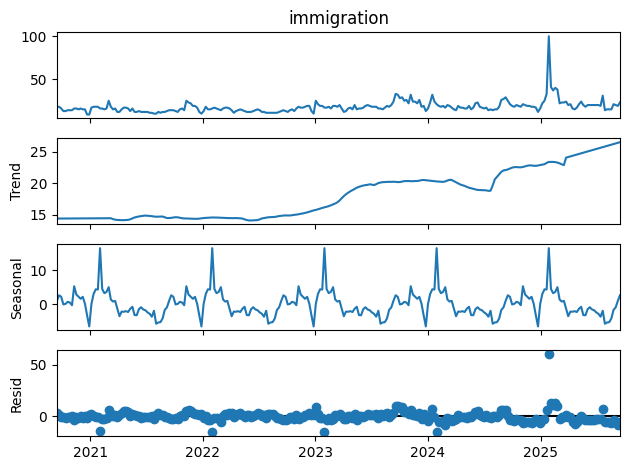

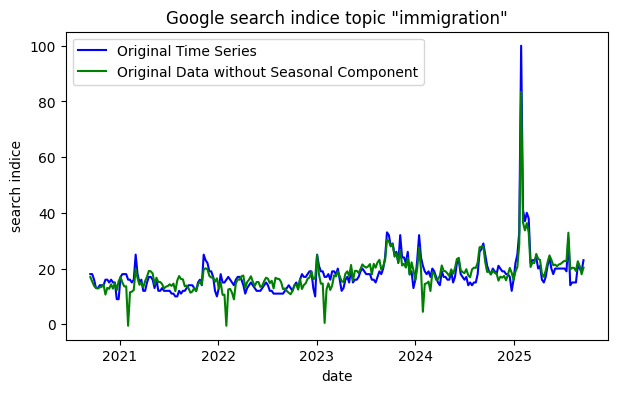

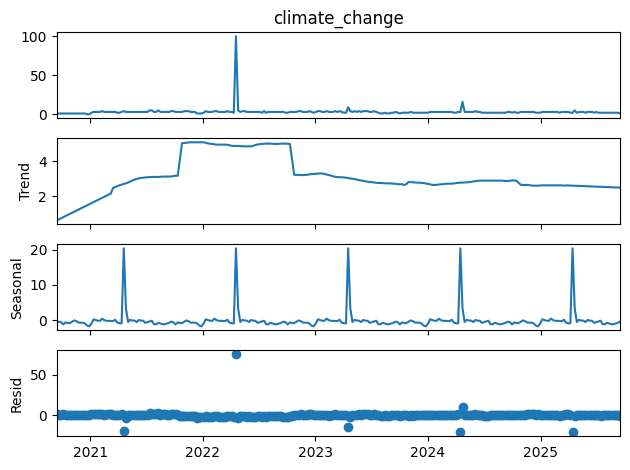

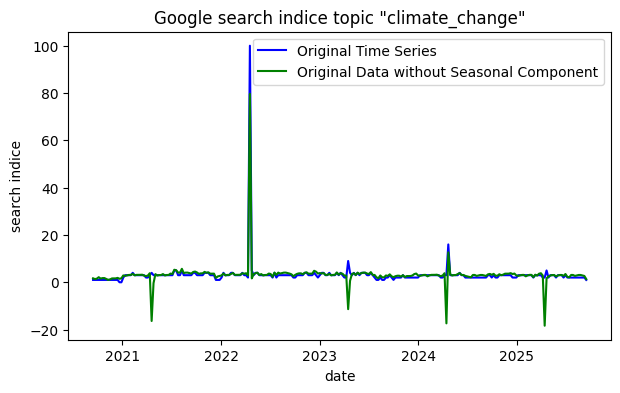

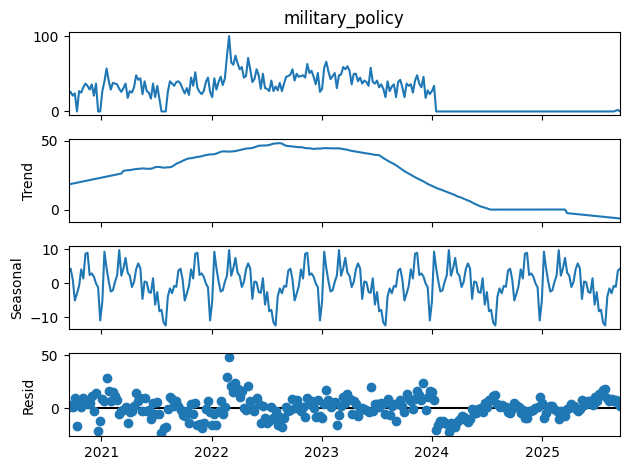

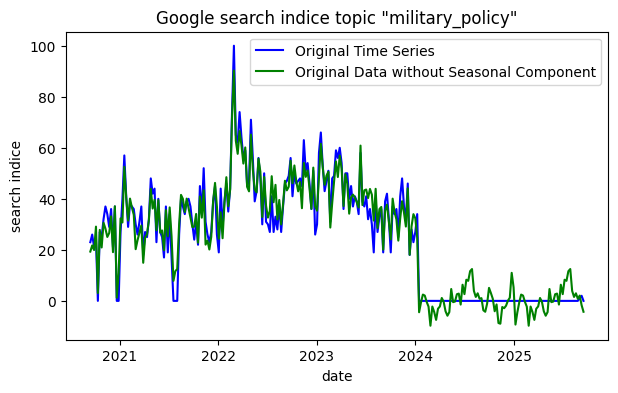

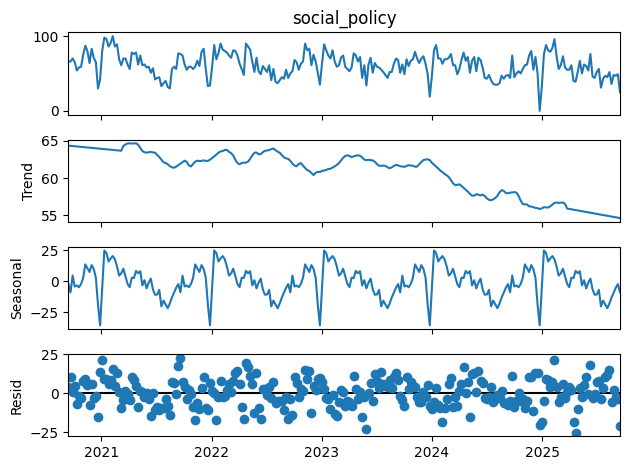

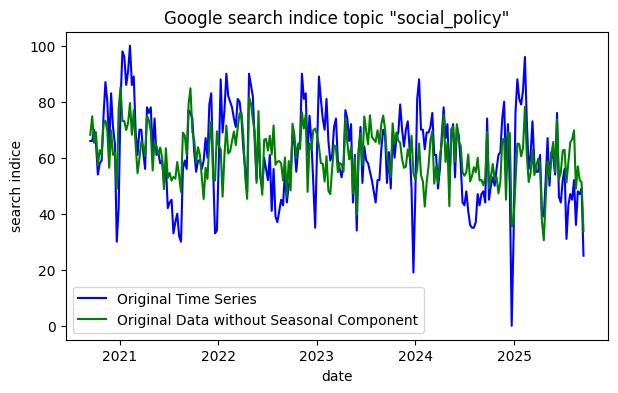

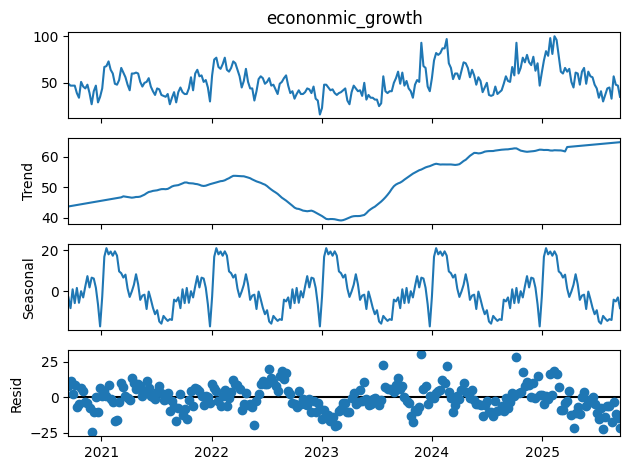

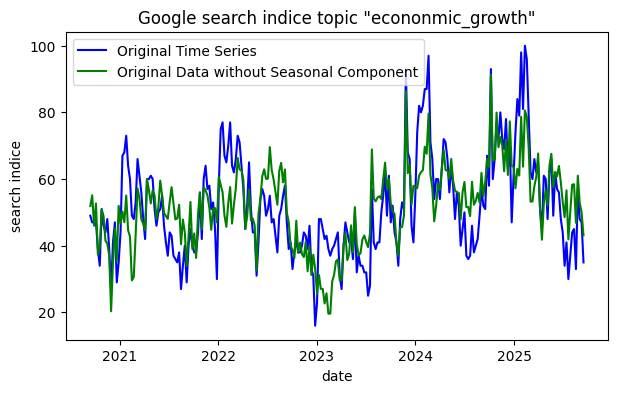

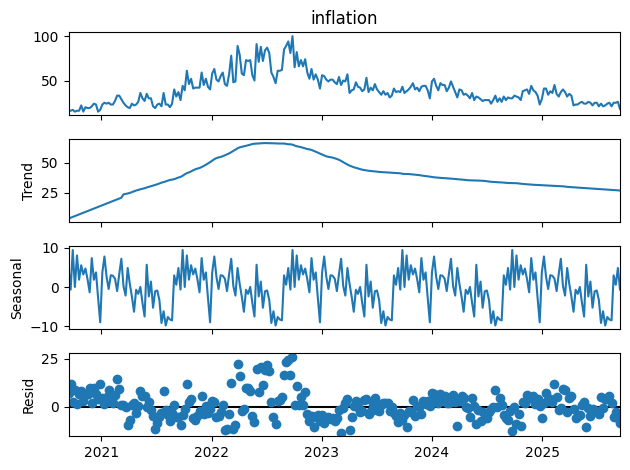

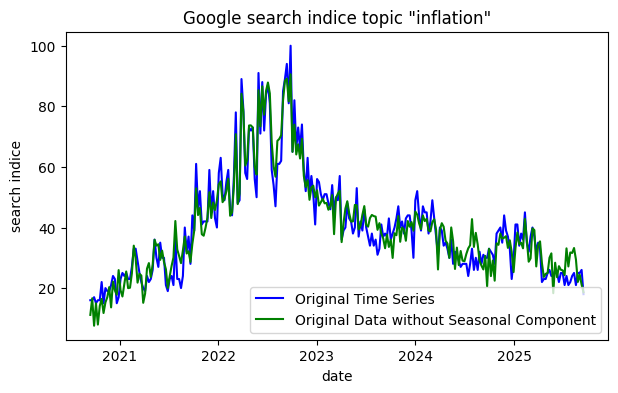

In [404]:
import pandas as pd
from statsmodels.tsa.seasonal import seasonal_decompose
#https://www.geeksforgeeks.org/machine-learning/seasonality-detection-in-time-series-data/
columns = ['immigration','climate_change','military_policy','social_policy', 'econonmic_growth', 'inflation']
columns_new =['immigration_new','climate_change_new','military_policy_new','social_policy_new', 'econonmic_growth_new', 'inflation_new']

data = topic_df.copy()
data = data.drop_duplicates(subset='date', keep='first')
data = data.groupby(pd.Grouper(key='date', freq='W-MON')).sum()


for i,z in zip(columns, columns_new):
    result = seasonal_decompose(data[i], model='additive', extrapolate_trend='freq')
    result.plot()
    plt.tight_layout()
    plt.show()
    plt.figure(figsize=(7, 4))
    plt.plot(data[i], label='Original Time Series', color='blue')
    data[z] = data[i] - result.seasonal
    plt.plot(data[z],label='Original Data without Seasonal Component', color='green')
    plt.title(f'Google search indice topic "{i}"')
    plt.xlabel('date')
    plt.ylabel('search indice')
    plt.legend()
    plt.show()


### 2.2 Seasonal adjustment of immigration related search terms

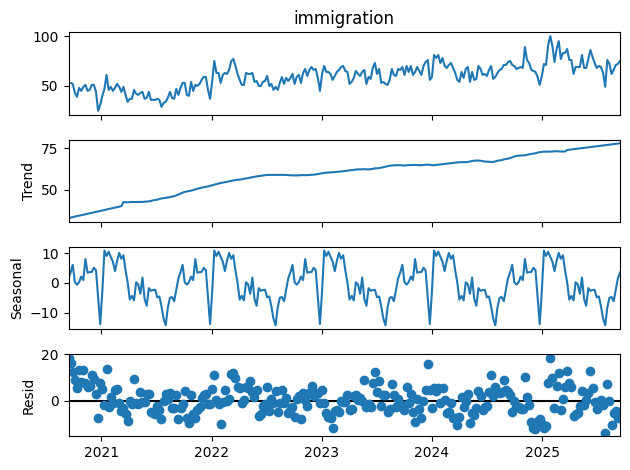

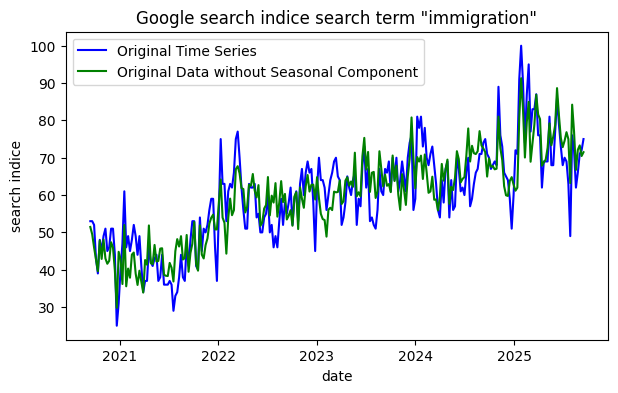

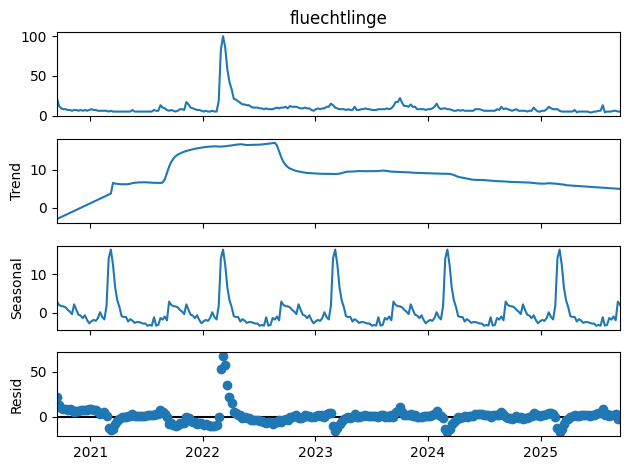

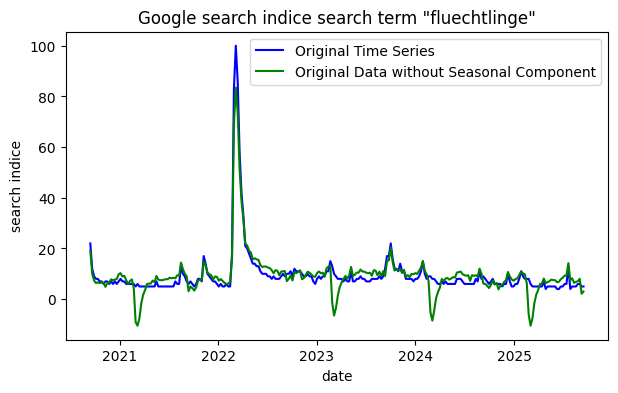

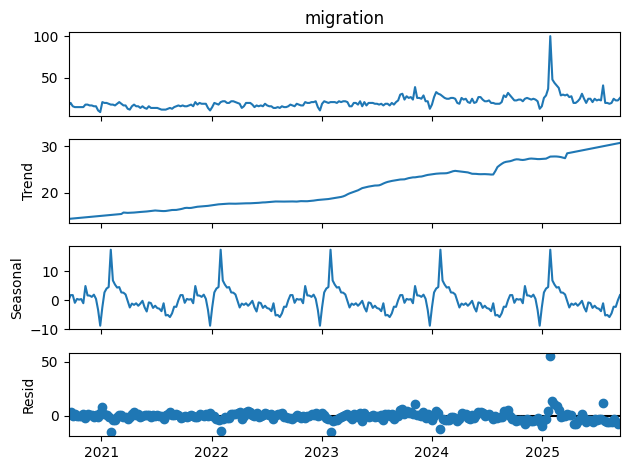

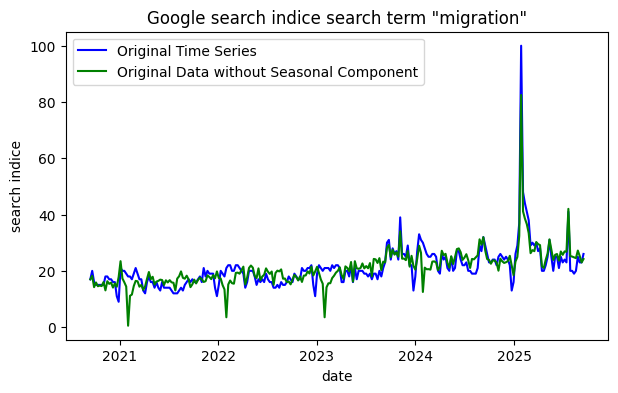

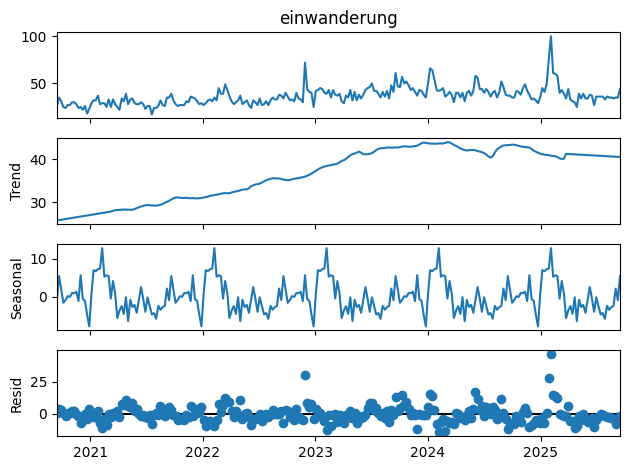

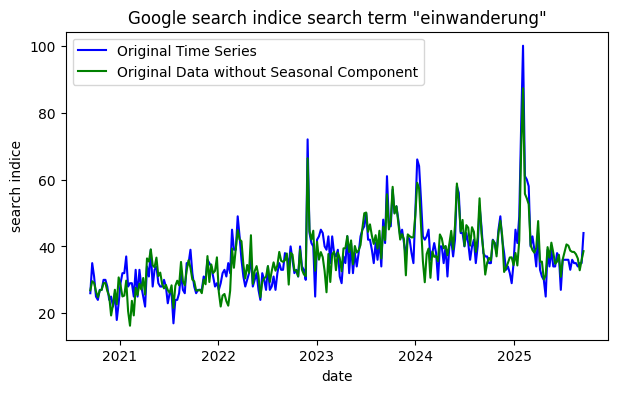

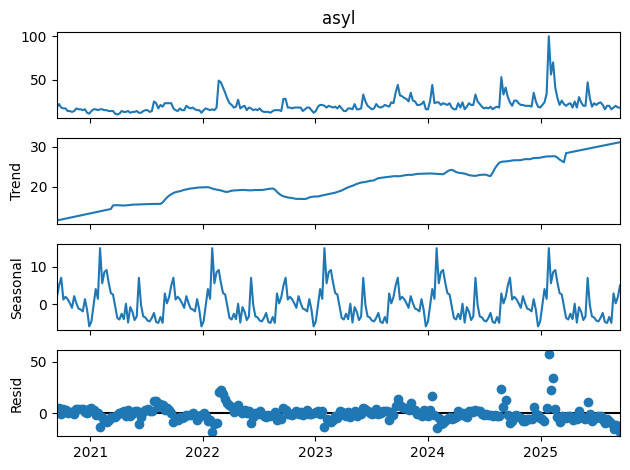

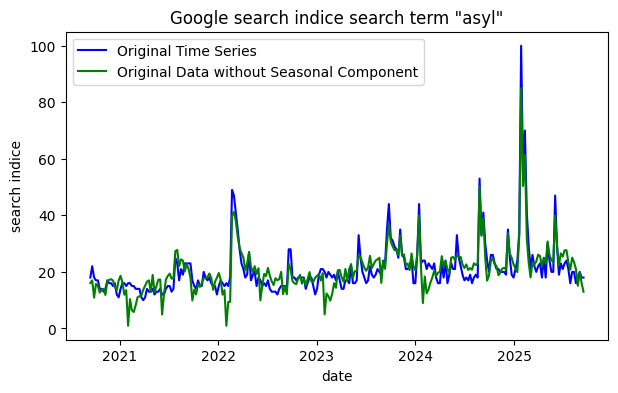

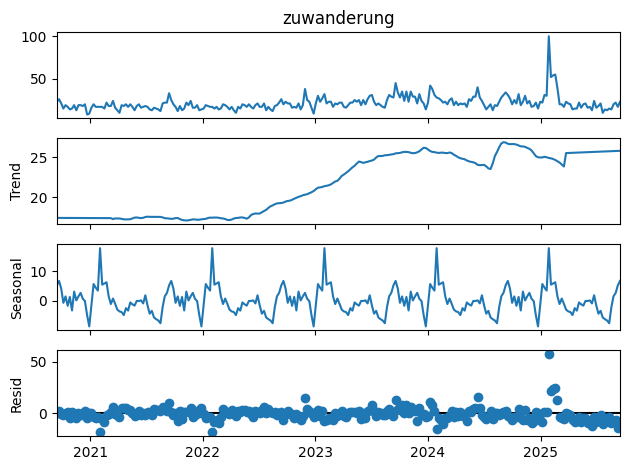

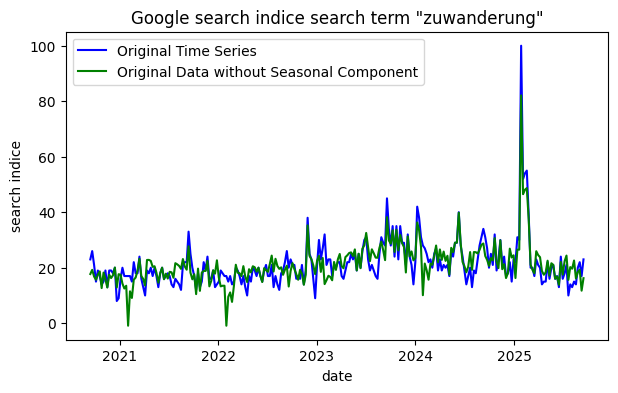

In [406]:
#https://www.geeksforgeeks.org/machine-learning/seasonality-detection-in-time-series-data/
terms = ['immigration','fluechtlinge','migration','einwanderung','asyl','zuwanderung']
terms_new = ['immigration_new','fluechtlinge_new','migration_new','einwanderung_new','asyl_new','zuwanderung_new']

term_data = term_df.copy()
term_data = term_data.drop_duplicates(subset='date', keep='first')
term_data = term_data.groupby(pd.Grouper(key='date', freq='W-MON')).sum()



for i,z in zip(terms, terms_new):
    result = seasonal_decompose(term_data[i], model='additive', extrapolate_trend='freq')
    result.plot()
    plt.tight_layout()
    plt.show()
    plt.figure(figsize=(7, 4))
    plt.plot(term_data[i], label='Original Time Series', color='blue')
    term_data[z] = term_data[i] - result.seasonal
    plt.plot(term_data[z],label='Original Data without Seasonal Component', color='green')
    plt.title(f'Google search indice search term "{i}"')
    plt.xlabel('date')
    plt.ylabel('search indice')
    plt.legend()
    plt.show()

### 2.3 Seasonal adjustment MIP data

In [ ]:
# interpolating mip data to make alignement easier with weekly google trends data
mip_data = mip_df_filtered.copy()
mip_data['date'] = pd.to_datetime(mip_data['year'].astype(str) + mip_data['week'].astype(str) + '1',format='%G%V%u')
mip_data = mip_data.set_index('date')
all_weeks = pd.date_range(mip_data.index.min(), mip_data.index.max(), freq='W-MON')
mip_data = mip_data.reindex(all_weeks)

mip_data[matched_topics] = mip_data[matched_topics].interpolate()
mip_data['year'] = mip_data.index.isocalendar().year
mip_data['week'] = mip_data.index.isocalendar().week

mip_data

,year,week,mip_matched_Umweltschutz Klimawandel Artenschutz,mip_matched_Energiewende erneuerbare Energien CO2-Steuer Kohleausstieg,mip_matched_Ausländer Zuwanderung Integration Asyl,mip_matched_Wirtschaftslage,mip_matched_Lebenshaltungskosten Preise Inflation,mip_matched_Krieg Ukraine Kriegsangst Russland Putin,mip_matched_Frieden Entspannung,mip_matched_soziales Gefälle Gerechtigkeit
2020-01-13,2020,3,36.849132,3.938585,15.620828,3.204272,0.467290,0.200267,1.735648,6.675567
2020-01-20,2020,4,33.163135,4.155259,15.424434,2.980063,0.759839,0.159883,1.658153,7.087509
2020-01-27,2020,5,29.477137,4.371933,15.228040,2.755855,1.052388,0.119498,1.580659,7.499451
2020-02-03,2020,6,25.791139,4.588608,15.031646,2.531646,1.344937,0.079114,1.503165,7.911392
2020-02-10,2020,7,22.919580,3.810831,19.248885,2.637485,1.092651,0.076125,1.429590,7.276728
...,...,...,...,...,...,...,...,...,...,...
2024-01-22,2024,4,7.216495,1.723582,12.564433,19.861469,3.511598,6.507732,0.000000,3.592139
2024-01-29,2024,5,6.997085,2.753482,12.601231,17.784257,4.535147,5.280207,0.000000,3.952057
2024-02-05,2024,6,7.084252,2.980611,11.986908,16.846450,4.946093,6.630961,0.000000,3.671646
2024-02-12,2024,7,7.171420,3.207739,11.372586,15.908643,5.357039,7.981715,0.000000,3.391234


In [361]:
matched_topics

['mip_matched_Umweltschutz Klimawandel Artenschutz',
 'mip_matched_Energiewende erneuerbare Energien CO2-Steuer Kohleausstieg',
 'mip_matched_Ausländer Zuwanderung Integration Asyl',
 'mip_matched_Wirtschaftslage',
 'mip_matched_Lebenshaltungskosten Preise Inflation',
 'mip_matched_Krieg Ukraine Kriegsangst Russland Putin',
 'mip_matched_Frieden Entspannung',
 'mip_matched_soziales Gefälle Gerechtigkeit']

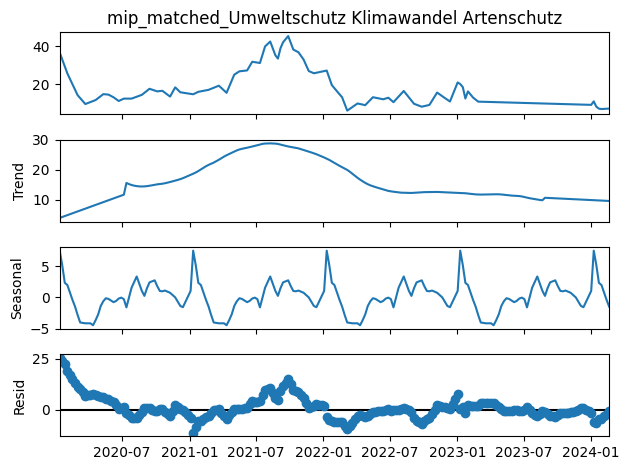

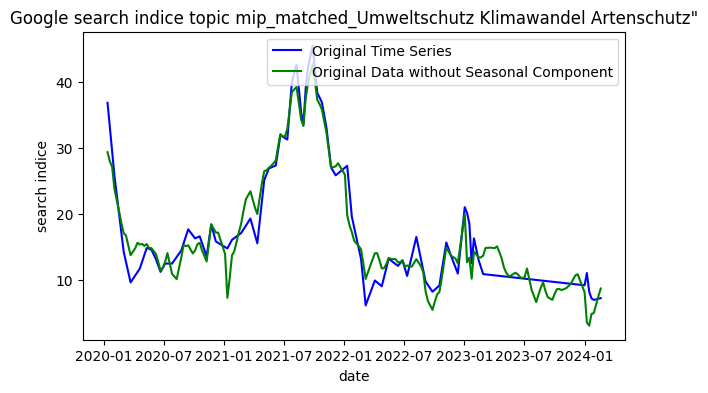

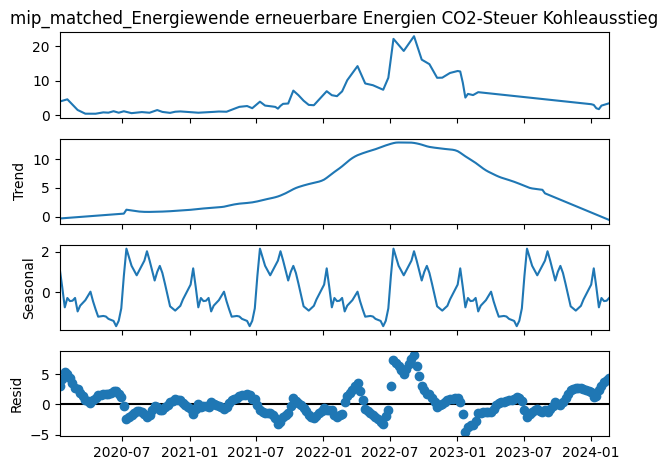

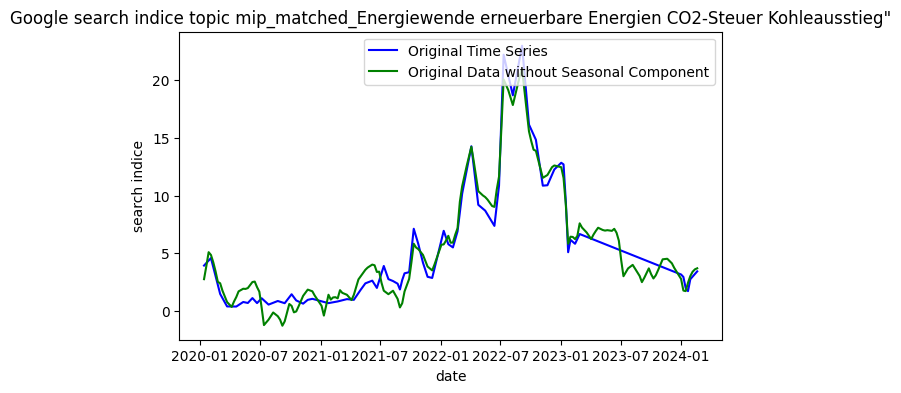

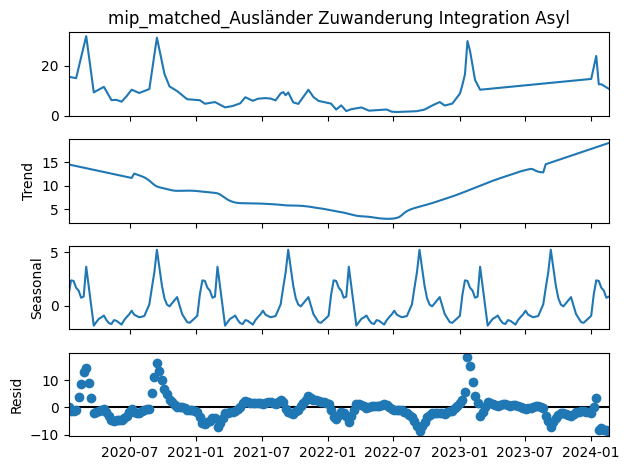

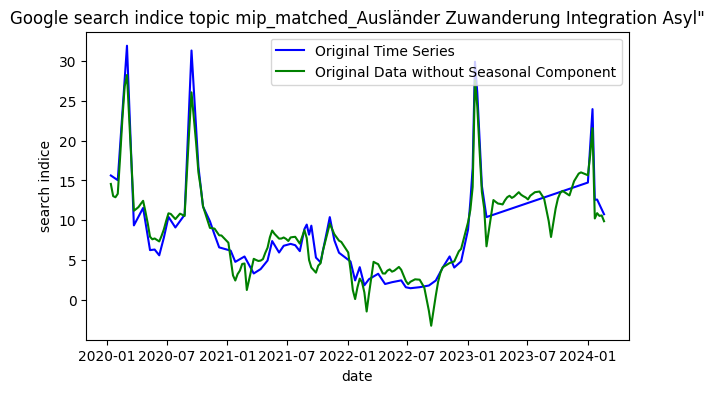

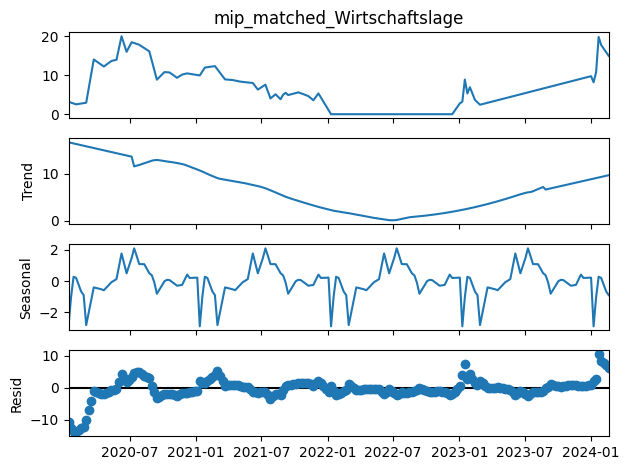

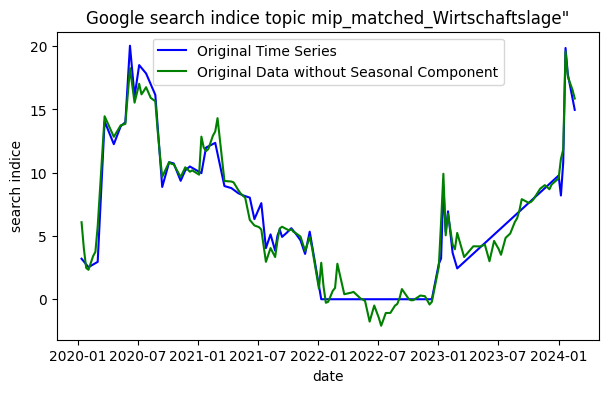

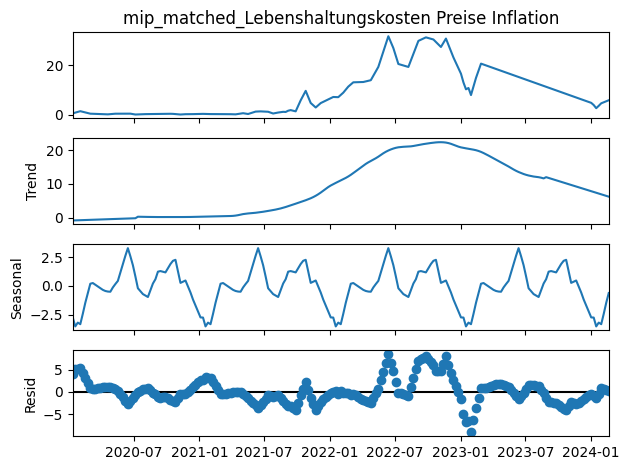

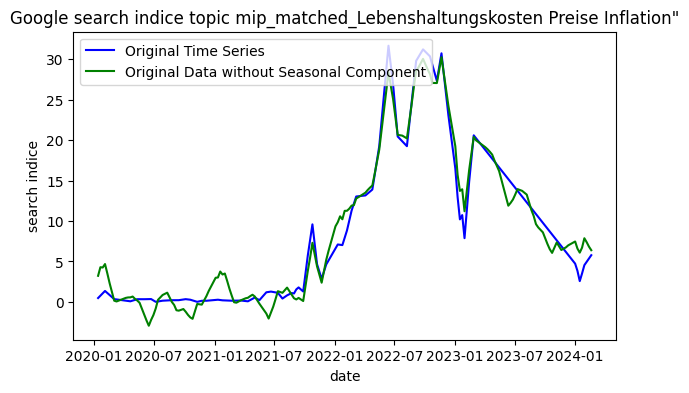

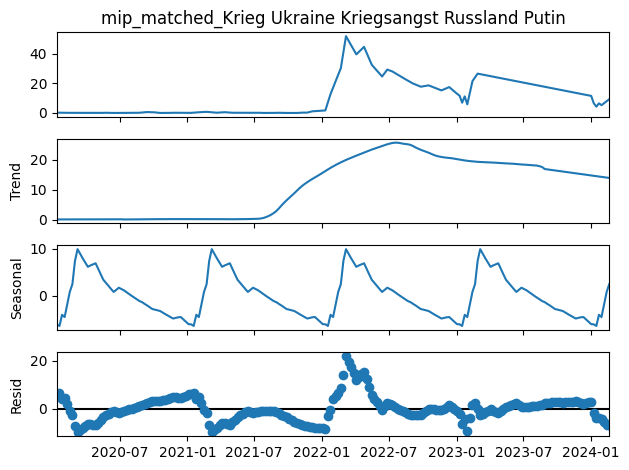

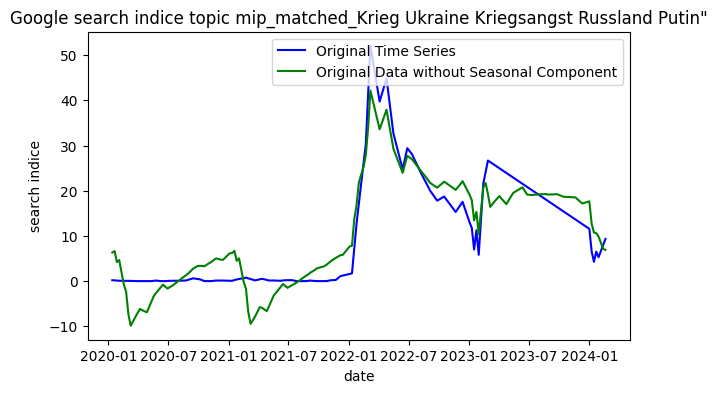

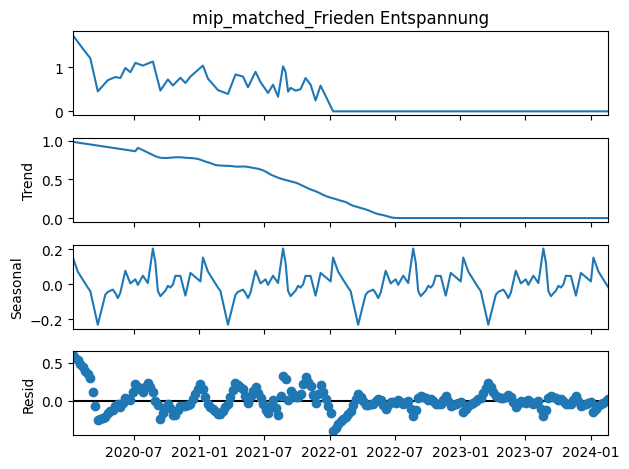

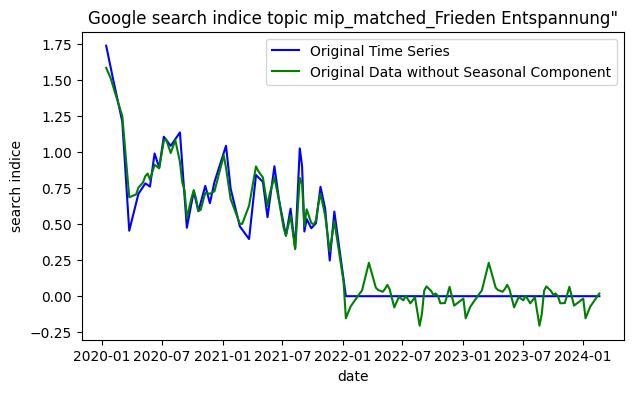

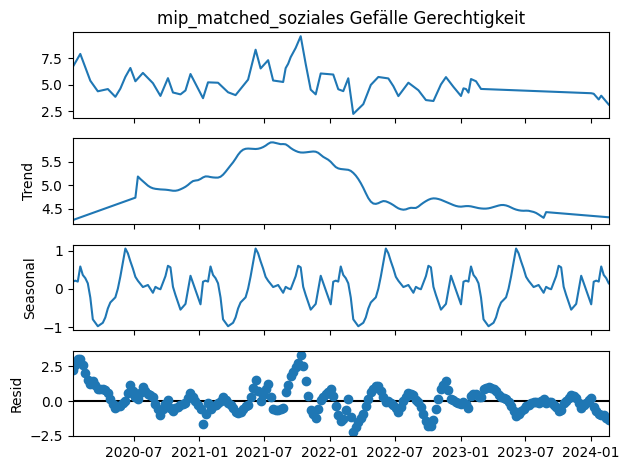

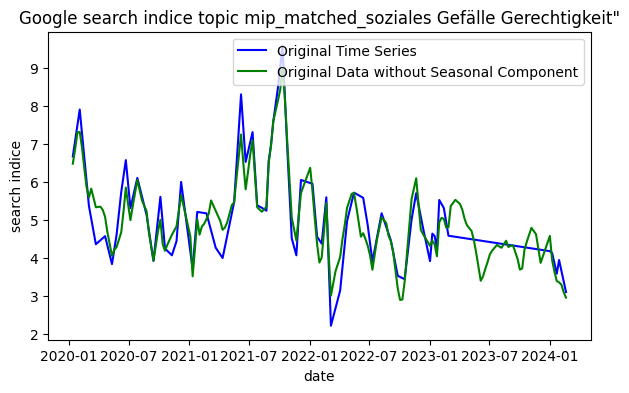

In [412]:
mip_columns_new = ['mip_climate_new','mip_energy_new','mip_immigration_new','mip_economy_new','mip_inflation_new',
                   'mip_war_new','mip_peace_new','mip_social_new']

for i,z in zip(matched_topics, mip_columns_new):
    result = seasonal_decompose(mip_data[i], model='additive', extrapolate_trend='freq')
    result.plot()
    plt.tight_layout()
    plt.show()
    plt.figure(figsize=(7, 4))
    plt.plot(mip_data[i], label='Original Time Series', color='blue')
    mip_data[z] = mip_data[i] - result.seasonal
    plt.plot(mip_data[z],label='Original Data without Seasonal Component', color='green')
    plt.title(f'Google search indice topic {i}"')
    plt.xlabel('date')
    plt.ylabel('search indice')
    plt.legend()
    plt.show()

### 2.4 Criterion Validity for divers issue salient topics

In [414]:
# testing for for stationarity accoridng to Mellon 2014
for i in columns_new:
    result = adfuller(data[i].dropna())

    if result[1] < 0.05 : print(f"{i} is stationary (p-value < 0.05).")
    else:
        print(f"{i} is not stationary (p-value >= 0.05).")

print("")

# mip series
for i in mip_columns_new:
    result = adfuller(mip_data[i].dropna())

    if result[1] < 0.05 : print(f"{i} is stationary (p-value < 0.05).")
    else:
        print(f"{i} is not stationary (p-value >= 0.05).")

immigration_new is stationary (p-value < 0.05).
climate_change_new is stationary (p-value < 0.05).
military_policy_new is not stationary (p-value >= 0.05).
social_policy_new is stationary (p-value < 0.05).
econonmic_growth_new is stationary (p-value < 0.05).
inflation_new is not stationary (p-value >= 0.05).

mip_climate_new is not stationary (p-value >= 0.05).
mip_energy_new is not stationary (p-value >= 0.05).
mip_immigration_new is stationary (p-value < 0.05).
mip_economy_new is not stationary (p-value >= 0.05).
mip_inflation_new is not stationary (p-value >= 0.05).
mip_war_new is not stationary (p-value >= 0.05).
mip_peace_new is not stationary (p-value >= 0.05).
mip_social_new is stationary (p-value < 0.05).


According to Mellon (2014) the following search indices are valid for OLS Regression because they are both non-stationary
- immigration and mip_immigration 
- social policy and mip_social

following can be regressed but residuals have to be checked for non-stationary
- mip_war / mip_peace and military policies
- inflation and mip_inflation


In [ ]:
# OLS regression between search indices and mip questions even thoiugh accoring to Mellon most indices are not valid 
merge_df = pd.merge(mip_data, data, on=['year','week'])
dependent = ['mip_immigration_new', 'mip_peace_new', 'mip_war_new', 'mip_social_new', 'mip_inflation_new']
independent = ['immigration_new','military_policy_new', 'military_policy_new', 'social_policy_new', 'inflation_new']

for i,z in zip(dependent, independent):
    #define predictor and response variables
    y = merge_df[i]
    x = merge_df[z]

    #add constant to predictor variables
    x = sm.add_constant(x)

    #fit linear regression model
    model = sm.OLS(y, x).fit(cov_type='HAC', cov_kwds={'maxlags':2})
    result = adfuller(model.resid.dropna())

    print(f'Regression between {z} and {i}')
    if model.pvalues[z]<0.05:
        print(f"Search indice significant! (p-value={model.pvalues[z]})")
        print(f'{round((model.rsquared*100),3)} % of variance are explained by search indice') 
    elif model.pvalues[z]>=0.05: 
        print(f"Search indice is not significant! (p-value={model.pvalues[z]})")
    if result[1] < 0.05: 
        print(f'Regression residuals between {z} and {i} are stationary')
    elif result[1] > 0.05:
        print(f'Regression residuals between {z} and {i} are NOT stationary')
    print("")

Regression between immigration_new and mip_immigration_new
Search indice significant! (p-value=0.007614956389058281)
11.16 % of variance are explained by search indice
Regression residuals between immigration_new and mip_immigration_new are NOT stationary

Regression between military_policy_new and mip_peace_new
Search indice significant! (p-value=0.013310155335220494)
8.044 % of variance are explained by search indice
Regression residuals between military_policy_new and mip_peace_new are NOT stationary

Regression between military_policy_new and mip_war_new
Search indice significant! (p-value=2.1499620488764527e-09)
30.426 % of variance are explained by search indice
Regression residuals between military_policy_new and mip_war_new are NOT stationary

Regression between social_policy_new and mip_social_new
Search indice is not significant! (p-value=0.442728547611837)
Regression residuals between social_policy_new and mip_social_new are stationary

Regression between inflation_new and m

In [616]:
for i,z in zip(dependent, independent):
    r, p = pearsonr(merge_df[i], merge_df[z])
    print(f"correlation of {i} and {z}: r = {r:.2f}, p = {p:.4f}")

correlation of mip_immigration_new and immigration_new: r = 0.33, p = 0.0000
correlation of mip_peace_new and military_policy_new: r = -0.28, p = 0.0001
correlation of mip_war_new and military_policy_new: r = 0.55, p = 0.0000
correlation of mip_social_new and social_policy_new: r = -0.08, p = 0.3035
correlation of mip_inflation_new and inflation_new: r = 0.82, p = 0.0000


Results show: 
- Immigration is significant but explains only 11 % of the variance in the corresponding MIP question
- mip_war / mip_peace with military policies are significant but residuals are non stationary => REJECT seach indice
- mip_social and social_policies are not significant => REJECT

Conclusion: Immigration is the only valid search indice but weak to measure issue salience according to Mellon's (2014) validation strategy

### 2.5 Criterion Validity of immigration related terms

In [430]:
# term time series. 
# we know the stationarity of MIP question as criterion validity
# mip_immigration_new is not stationary (p-value >= 0.05).
for i in terms_new:
    result = adfuller(term_data[i].dropna())
    if result[1] < 0.05 : print(f"{i} is stationary (p-value < 0.05).")
    else:
        print(f"{i} is not stationary (p-value >= 0.05).")

# only immigration and einwanderung are valid here

immigration_new is not stationary (p-value >= 0.05).
fluechtlinge_new is stationary (p-value < 0.05).
migration_new is stationary (p-value < 0.05).
einwanderung_new is not stationary (p-value >= 0.05).
asyl_new is stationary (p-value < 0.05).
zuwanderung_new is stationary (p-value < 0.05).


All search indices are valid because the MIP question is stationary. 
Only "Immigration" and "Einwanderung" have to be differenced before OLS regression to match order of integration with MIP series

In [617]:
# OLS regression between search term indices and mip questions 
merge_df = pd.merge(mip_data, term_data, on=['year','week'])

for i in ['fluechtlinge_new','migration_new', 'asyl_new', 'zuwanderung_new']:
    #define predictor and response variables
    y = merge_df['mip_immigration_new']
    x = merge_df[i]

    #add constant to predictor variables
    x = sm.add_constant(x)

    #fit linear regression model
    model = sm.OLS(y, x).fit(cov_type='HAC', cov_kwds={'maxlags':2})

    print(f'Regression between mip immigration question and {i}')
    if  model.pvalues[i] < 0.05:
        print(f"Search indice significant! (p-value={model.pvalues[i]})")
        print(f'{round((model.rsquared*100),3)} % of variance are explained by search indice') 
    else: 
        print(f"Search indice is not significant! (p-value={model.pvalues[i]})")
    print("")

Regression between mip immigration question and fluechtlinge_new
Search indice is not significant! (p-value=0.06652169290686301)

Regression between mip immigration question and migration_new
Search indice significant! (p-value=0.03268558283526435)
7.955 % of variance are explained by search indice

Regression between mip immigration question and asyl_new
Search indice is not significant! (p-value=0.4178979854963575)

Regression between mip immigration question and zuwanderung_new
Search indice significant! (p-value=4.770915239498443e-07)
13.426 % of variance are explained by search indice



In [618]:
# neeed to differentiate to meet matching sattionarity
for i in ['immigration_new', 'einwanderung_new']:
    tempo = merge_df[['mip_immigration_new', i]].copy()
    tempo[i] = tempo[i].diff()
    tempo = tempo.dropna()

    y = tempo['mip_immigration_new']   # not differenced
    x = sm.add_constant(tempo[i])  

    model = sm.OLS(y, x).fit(cov_type='HAC', cov_kwds={'maxlags':2})

    print(f'Regression between mip immigration question and {i}')
    if  model.pvalues[i] < 0.05:
        print(f"Search indice significant! (p-value={model.pvalues[i]})")
        print(f'{round((model.rsquared*100),3)} % of variance are explained by search indice') 
    else: 
        print(f"Search indice is not significant! (p-value={model.pvalues[i]})")
    print("")

Regression between mip immigration question and immigration_new
Search indice is not significant! (p-value=0.6740828659190514)

Regression between mip immigration question and einwanderung_new
Search indice is not significant! (p-value=0.3839645711224583)



In [558]:
for i in terms_new:
    r, p = pearsonr(merge_df[i], merge_df['mip_immigration_new'])
    print(f"correlation of {i}: r = {r:.2f}, p = {p:.4f}")

correlation of immigration_new: r = 0.22, p = 0.0028
correlation of fluechtlinge_new: r = -0.15, p = 0.0497
correlation of migration_new: r = 0.28, p = 0.0001
correlation of einwanderung_new: r = 0.29, p = 0.0001
correlation of asyl_new: r = 0.11, p = 0.1306
correlation of zuwanderung_new: r = 0.37, p = 0.0000


Result: 
- while some search terms are significant all of them do not sufficiently predict the MIP question of the politbarometer

Conclusion: According to Mellon (2014) method we should not use these search terms as a proxy for issue salience. 

## 3. Relationship between Google search indices and polling results 

### 3.1 Seasonal Adjusmtent of polling data

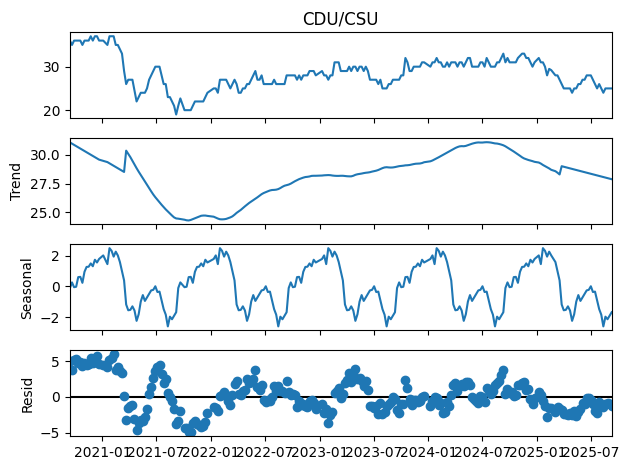

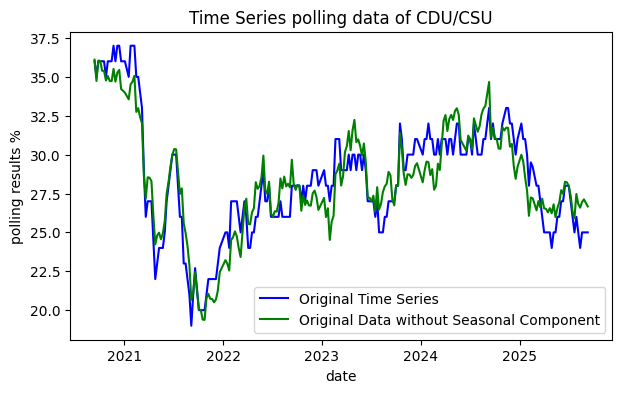

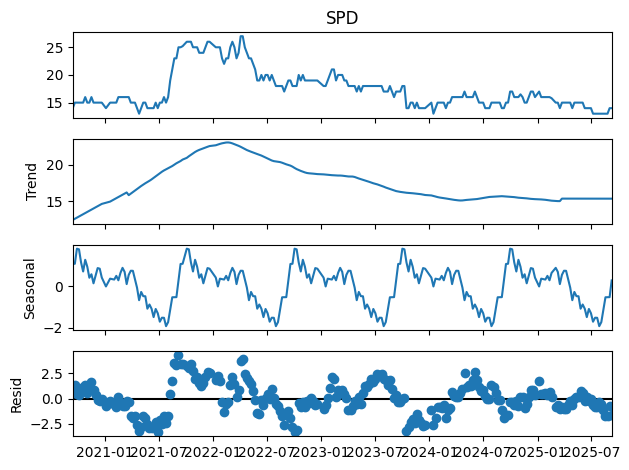

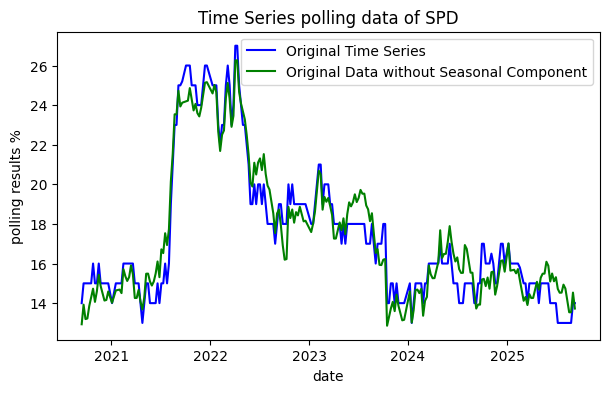

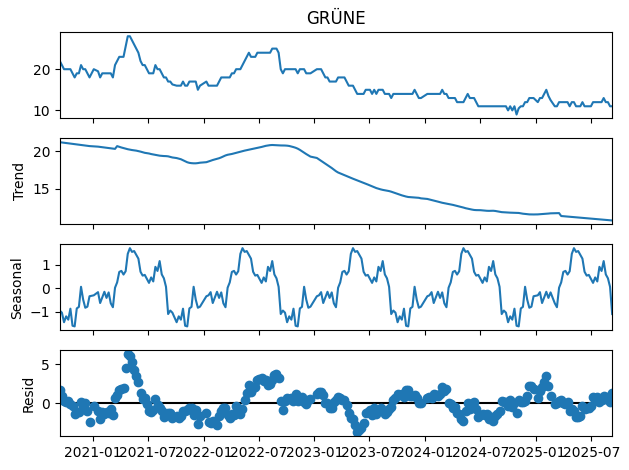

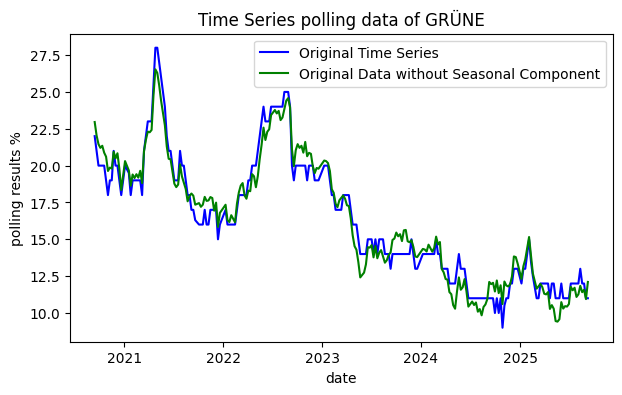

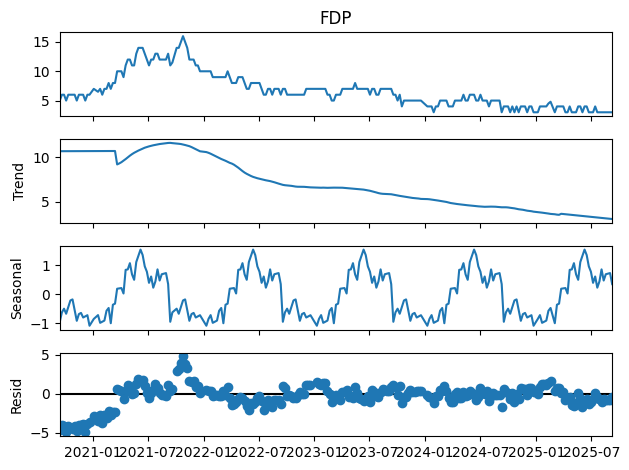

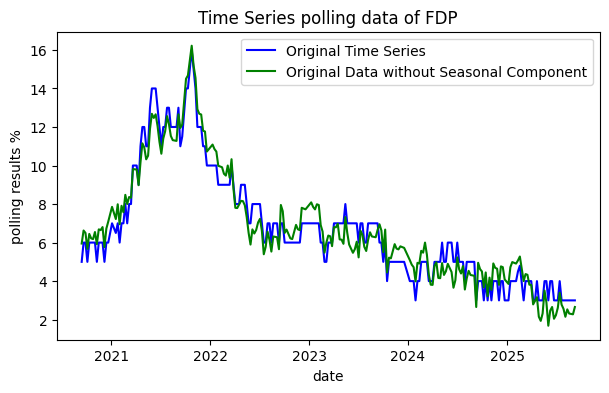

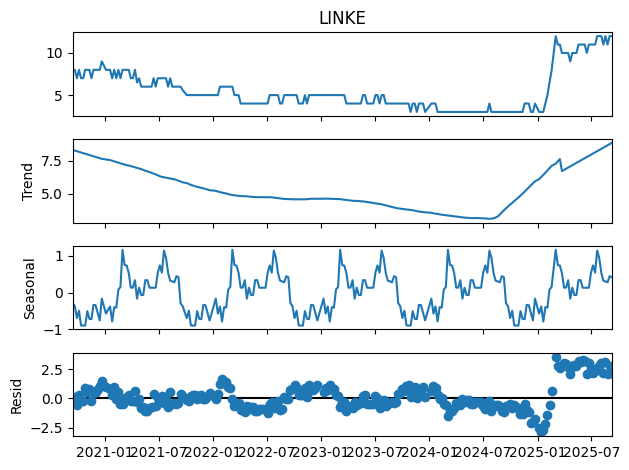

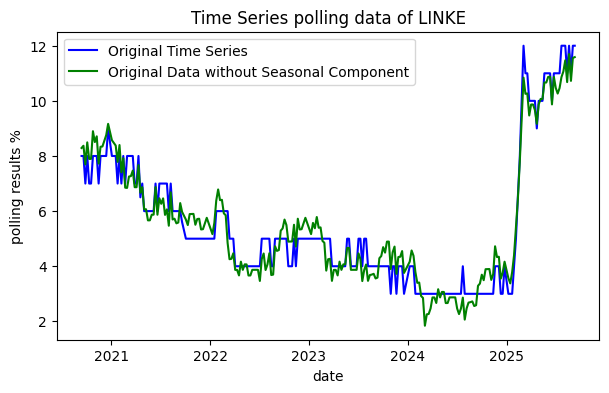

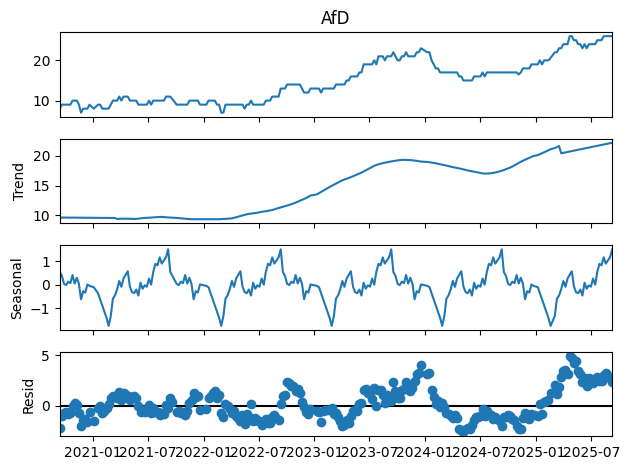

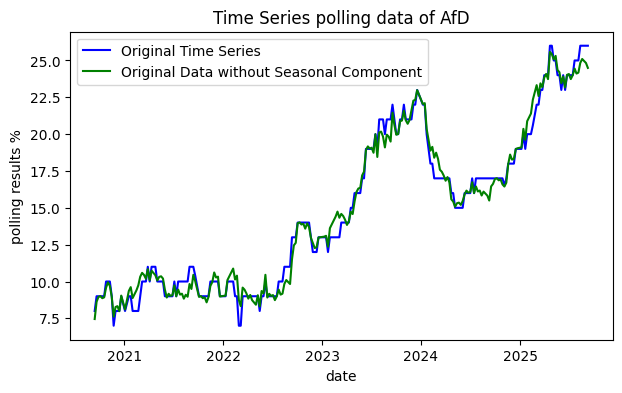

In [ ]:
# trying to align both time series monthly 
polling_data = polling_df.copy()
polling_data['date'] = pd.to_datetime(polling_data['year'].astype(str) + polling_data['week'].astype(str) + '1',format='%G%V%u')
polling_data = polling_data.set_index('date')
#all_weeks = pd.date_range(polling_data.index.min(), polling_data.index.max(), freq='W-MON')
#polling_data = polling_data.reindex(all_weeks)
parties = ['CDU/CSU', 'SPD', 'GRÜNE', 'FDP', 'LINKE', 'AfD',]
parties_new = ['CDU/CSU_new', 'SPD_new', 'GRÜNE_new', 'FDP_new', 'LINKE_new', 'AfD_new',]
polling_data[parties] = polling_data[parties].interpolate() # in case some weeks are 
polling_data['year'] = polling_data.index.isocalendar().year
polling_data['week'] = polling_data.index.isocalendar().week


for i,z in zip(parties, parties_new):
    result = seasonal_decompose(polling_data[i], model='additive', extrapolate_trend='freq', period = 50)
    #period 50 because these are 5 five years = same as google trends data
    #but not all years have 52 weeks so we use 50 instead becuase we got 250 observations up until now
    result.plot()
    plt.tight_layout()
    plt.show()
    plt.figure(figsize=(7, 4))
    plt.plot(polling_data[i], label='Original Time Series', color='blue')
    polling_data[z] = polling_data[i] - result.seasonal
    plt.plot(polling_data[z],label='Original Data without Seasonal Component', color='green')
    plt.title(f'Time Series polling data of {i}')
    plt.xlabel('date')
    plt.ylabel('polling results %')
    plt.legend()
    plt.show()

### 3.2 Analysis of divers issue salient topics

In [666]:
#align google trends data and polling results
gp_df = pd.merge(polling_data,data , on=['year','week'])
gp_df.head()

,year,week,CDU/CSU,SPD,GRÜNE,FDP,LINKE,AfD,BSW,Sonstige,...,social_policy,econonmic_growth,inflation,month,immigration_new,climate_change_new,military_policy_new,social_policy_new,econonmic_growth_new,inflation_new
0,2020,38,36.0,14.0,22.0,5.0,8.0,8.0,NaN,7.0,...,66,47,16,9,15.318844,1.356158,21.736221,74.801025,55.129712,16.628875
1,2020,39,35.0,15.0,21.0,6.0,8.0,9.0,NaN,6.0,...,70,47,17,9,13.776438,1.535140,19.928323,65.327797,45.991665,7.580861
2,2020,40,36.0,15.0,20.0,6.0,7.0,9.0,NaN,7.0,...,65,47,15,10,13.015321,2.151236,29.105023,69.106956,52.686694,14.971633
3,2020,41,36.0,15.0,20.0,5.0,8.0,9.0,NaN,7.0,...,54,39,16,10,12.842664,1.563486,3.068261,57.266884,37.337493,7.956635
4,2020,42,36.0,15.0,20.0,6.0,7.0,9.0,NaN,7.0,...,58,34,16,10,13.252700,1.769967,27.821884,62.759505,39.515215,14.110868


#### 3.2.1 Correlations between parties and issue salient topics

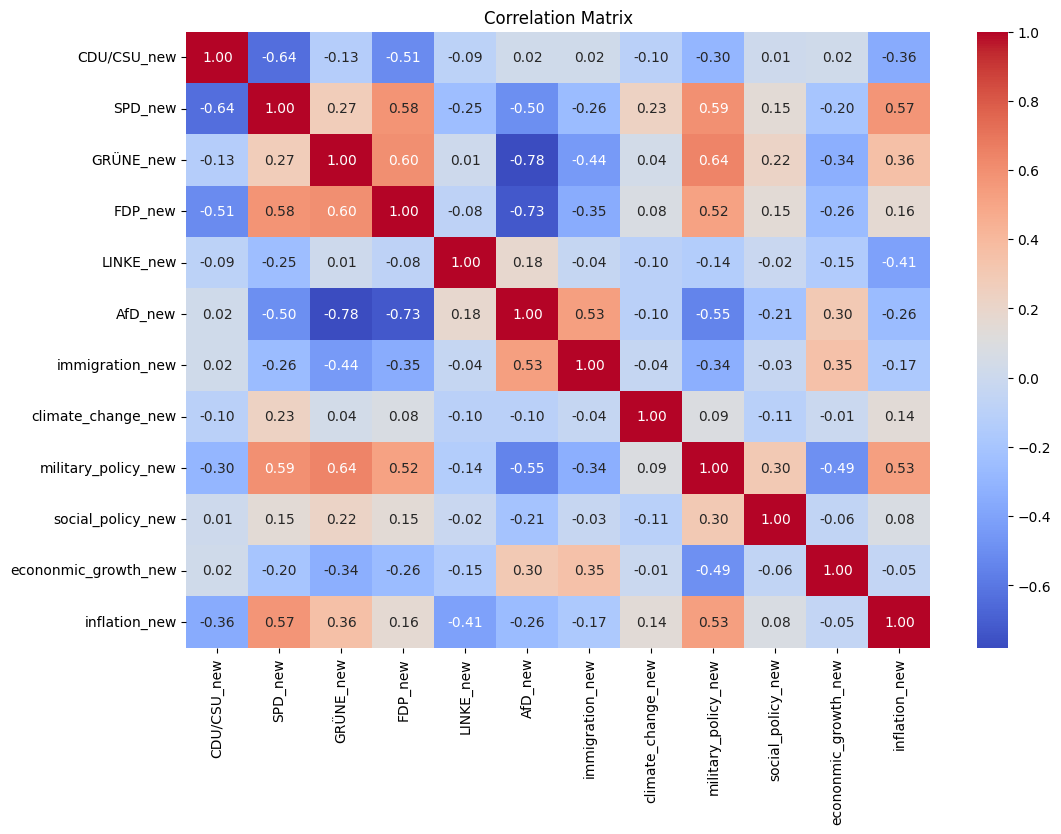

In [682]:
# Compute correlation matrix
corr_matrix = gp_df[parties_new + columns_new].corr()
corr_matrix = round(corr_matrix,2)
corr_matrix.to_csv('parties_topics_corr.csv', index=False) 

# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title("Correlation Matrix")
plt.show()

In [673]:
for i in columns_new:
    print(f"Correlations of {i}")
    for z in parties_new:
        r, p = pearsonr(gp_df[i], gp_df[z])
        print(f"correlation of {i} with {z}: r = {r:.2f}, p = {p:.4f}")
    print("")

Correlations of immigration_new
correlation of immigration_new with CDU/CSU_new: r = 0.02, p = 0.7007
correlation of immigration_new with SPD_new: r = -0.26, p = 0.0000
correlation of immigration_new with GRÜNE_new: r = -0.44, p = 0.0000
correlation of immigration_new with FDP_new: r = -0.35, p = 0.0000
correlation of immigration_new with LINKE_new: r = -0.04, p = 0.4812
correlation of immigration_new with AfD_new: r = 0.53, p = 0.0000

Correlations of climate_change_new
correlation of climate_change_new with CDU/CSU_new: r = -0.10, p = 0.1228
correlation of climate_change_new with SPD_new: r = 0.23, p = 0.0003
correlation of climate_change_new with GRÜNE_new: r = 0.04, p = 0.5474
correlation of climate_change_new with FDP_new: r = 0.08, p = 0.2328
correlation of climate_change_new with LINKE_new: r = -0.10, p = 0.1337
correlation of climate_change_new with AfD_new: r = -0.10, p = 0.1210

Correlations of military_policy_new
correlation of military_policy_new with CDU/CSU_new: r = -0.30

#### 3.2.3 OLS Regression between parties and issue salient topics

In [626]:
# checking for stationarity of party polling results
for i in parties_new:
    result = adfuller(polling_data[i].dropna())

    if result[1] < 0.05 : print(f"{i} is stationary (p-value < 0.05).")
    else:
        print(f"{i} is not stationary (p-value >= 0.05).")

CDU/CSU_new is not stationary (p-value >= 0.05).
SPD_new is not stationary (p-value >= 0.05).
GRÜNE_new is not stationary (p-value >= 0.05).
FDP_new is not stationary (p-value >= 0.05).
LINKE_new is not stationary (p-value >= 0.05).
AfD_new is not stationary (p-value >= 0.05).


In [ ]:
# matching topics with their non stationary parties 
dependent = ['GRÜNE_new','FDP_new', 'FDP_new','CDU/CSU_new', 'CDU/CSU_new' ]
independent = ['climate_change_new','econonmic_growth_new', 'inflation_new', 'econonmic_growth_new', 'inflation_new' ]


for i,z in zip(dependent, independent):
    #define predictor and response variables
    y = gp_df[i]
    x = gp_df[z]

    #add constant to predictor variables
    x = sm.add_constant(x)

    #fit linear regression model
    model = sm.OLS(y, x).fit(cov_type='HAC', cov_kwds={'maxlags':2})
    result = adfuller(model.resid.dropna())

    print(f'Regression between {z} and {i}')
    if model.pvalues[z]<0.05:
        print(f"Search indice significant! (p-value={model.pvalues[z]})")
        print(f'{round((model.rsquared*100),3)} % of variance are explained by search indice') 
    elif model.pvalues[z]>=0.05: 
        print(f"Search indice is not significant! (p-value={model.pvalues[z]})")
    if result[1] < 0.05: 
        print(f'Regression residuals between {z} and {i} are stationary')
    elif result[1] > 0.05:
        print(f'Regression residuals between {z} and {i} are NOT stationary')
    print("")


Regression between climate_change_new and GRÜNE_new
Search indice is not significant! (p-value=0.27238382581404486)
Regression residuals between climate_change_new and GRÜNE_new are NOT stationary

Regression between econonmic_growth_new and FDP_new
Search indice significant! (p-value=1.5655067331024322e-06)
6.597 % of variance are explained by search indice
Regression residuals between econonmic_growth_new and FDP_new are NOT stationary

Regression between inflation_new and FDP_new
Search indice significant! (p-value=0.025571461143924033)
2.434 % of variance are explained by search indice
Regression residuals between inflation_new and FDP_new are NOT stationary

Regression between econonmic_growth_new and CDU/CSU_new
Search indice is not significant! (p-value=0.8438574384964417)
Regression residuals between econonmic_growth_new and CDU/CSU_new are NOT stationary

Regression between inflation_new and CDU/CSU_new
Search indice significant! (p-value=6.0617752227864083e-05)
13.074 % of va

In [ ]:
# neeed to differentiate  parties to meet matching sattionarity

dependent = ['AfD_new','LINKE_new','SPD_new']
independent = ['immigration_new', 'social_policy_new','social_policy_new' ]


for i,z in zip(dependent, independent):
    tempo = gp_df[[i,z]].copy()
    tempo[i] = tempo[i].diff()       
    tempo = tempo.dropna()                       

    y = tempo[i]
    x = sm.add_constant(tempo[z])

    #fit linear regression model
    model = sm.OLS(y, x).fit(cov_type='HAC', cov_kwds={'maxlags':2})
    result = adfuller(model.resid.dropna())

    print(f'Regression between {z} and {i}')
    if model.pvalues[z]<0.05:
        print(f"Search indice significant! (p-value={model.pvalues[z]})")
        print(f'{round((model.rsquared*100),3)} % of variance are explained by search indice') 
    elif model.pvalues[z]>=0.05: 
        print(f"Search indice is not significant! (p-value={model.pvalues[z]})")
    if result[1] < 0.05: 
        print(f'Regression residuals between {z} and {i} are stationary')
    elif result[1] > 0.05:
        print(f'Regression residuals between {z} and {i} are NOT stationary')
    print("")

Regression between immigration_new and AfD_new
Search indice is not significant! (p-value=0.6070926793574987)
Regression residuals between immigration_new and AfD_new are stationary

Regression between social_policy_new and LINKE_new
Search indice is not significant! (p-value=0.5883301326589594)
Regression residuals between social_policy_new and LINKE_new are stationary

Regression between social_policy_new and SPD_new
Search indice is not significant! (p-value=0.16268142123431717)
Regression residuals between social_policy_new and SPD_new are stationary



#### 3.2.4 Autoregressive models

In [686]:
from statsmodels.tsa.ar_model import AutoReg
for i in range(1,20):
    model = AutoReg(gp_df['CDU/CSU'], lags=i, missing='drop').fit()
    print(f"lag: {i} with a of BIC: {model.bic}")

lag: 1 with a of BIC: 745.9195069747228
lag: 2 with a of BIC: 749.1521369489827
lag: 3 with a of BIC: 751.0394264749451
lag: 4 with a of BIC: 753.9305452989547
lag: 5 with a of BIC: 756.0136548688976
lag: 6 with a of BIC: 758.3690167854934
lag: 7 with a of BIC: 759.8677418340324
lag: 8 with a of BIC: 761.2379362929507
lag: 9 with a of BIC: 762.7398241697794
lag: 10 with a of BIC: 766.0293022118946
lag: 11 with a of BIC: 766.6552621695574
lag: 12 with a of BIC: 766.6546635980803
lag: 13 with a of BIC: 766.1677287356792
lag: 14 with a of BIC: 768.5507929979401
lag: 15 with a of BIC: 770.8531822901055
lag: 16 with a of BIC: 774.0606275374723
lag: 17 with a of BIC: 777.335438195939
lag: 18 with a of BIC: 774.5107988892482
lag: 19 with a of BIC: 777.342031927824


In [687]:
for i in range(1,20):
    model = AutoReg(gp_df['CDU/CSU'], lags=i, missing='drop', exog=gp_df['inflation']).fit()
    print(f"lag: {i} with a of BIC: {model.bic}")

lag: 1 with a of BIC: 751.3893553911886
lag: 2 with a of BIC: 754.6249001072612
lag: 3 with a of BIC: 756.482142368033
lag: 4 with a of BIC: 759.4044521080325
lag: 5 with a of BIC: 761.5145799976073
lag: 6 with a of BIC: 763.8568919173919
lag: 7 with a of BIC: 765.2792410673521
lag: 8 with a of BIC: 766.6851520883254
lag: 9 with a of BIC: 768.2240429923855
lag: 10 with a of BIC: 771.5098810552595
lag: 11 with a of BIC: 772.1310799764678
lag: 12 with a of BIC: 772.0861668225859
lag: 13 with a of BIC: 771.5187371450577
lag: 14 with a of BIC: 773.9729979605645
lag: 15 with a of BIC: 776.1718030650309
lag: 16 with a of BIC: 779.3651007507065
lag: 17 with a of BIC: 782.6357411988038
lag: 18 with a of BIC: 779.867994216237
lag: 19 with a of BIC: 782.7110394987333


In [704]:
autoreg = AutoReg(gp_df['CDU/CSU_new'], lags=1, missing='drop').fit()
combined_model = AutoReg(gp_df['CDU/CSU_new'], lags=0, missing='drop', exog=gp_df['inflation_new']).fit()
combined_lagged = AutoReg(gp_df['CDU/CSU_new'], lags=1, missing='drop', exog=gp_df['inflation_new']).fit()

print(f"Autoregressive model lag = 1 BIC:  {round(autoreg.bic,3)}")
print(f"Autoregressive model (lag = 0) combined with immigration search terms model BIC:  {round(combined_model.bic,3)}")
print(f"Autoregressive model (lag = 1) combined with immigration search terms model BIC: {round(combined_lagged.bic,3)}")

Autoregressive model lag = 1 BIC:  710.765
Autoregressive model (lag = 0) combined with immigration search terms model BIC:  1310.781
Autoregressive model (lag = 1) combined with immigration search terms model BIC: 716.147


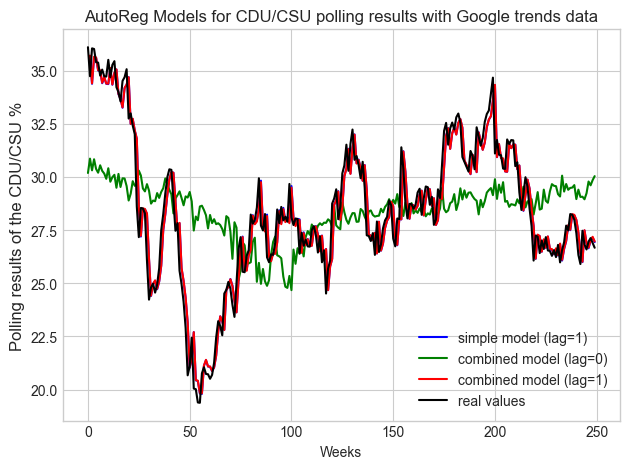

In [718]:
# Creating a line chart showing the three models plotted against the real value of AFD
plt.plot(autoreg.fittedvalues, label="simple model (lag=1)", color='blue')
plt.plot(combined_model.fittedvalues, label="combined model (lag=0)", color='green')
plt.plot(combined_lagged.fittedvalues, label="combined model (lag=1)", color='red')
plt.plot (gp_df['CDU/CSU_new'], label= "real values", color="black")

# Add labels and title
plt.title("AutoReg Models for CDU/CSU polling results with Google trends data")
plt.xlabel("Weeks")
plt.ylabel("Polling results of the CDU/CSU %", fontsize=12)
plt.legend()

plt.grid(True)
plt.tight_layout()
plt.show()

### 3.3 Analysis of immigration related search terms and AfD polling results

In [674]:
#align google trends data and polling results
pol_im_df = pd.merge(polling_data,term_data , on=['year','week'])
pol_im_df = pol_im_df[['year', 'week','AfD', 'AfD_new']+ terms+terms_new]
pol_im_df.head()

,year,week,AfD,AfD_new,immigration,fluechtlinge,migration,einwanderung,asyl,zuwanderung,immigration_new,fluechtlinge_new,migration_new,einwanderung_new,asyl_new,zuwanderung_new
0,2020,38,8.0,7.453622,53,12,20,35,22,26,49.484800,10.004678,18.204639,29.581535,16.990430,19.228246
1,2020,39,9.0,8.624993,52,9,16,31,18,21,45.949754,7.326736,14.199095,29.081808,10.888983,16.822420
2,2020,40,9.0,8.958363,43,8,15,25,17,15,42.783784,6.380869,15.869117,26.557784,15.752149,15.662560
3,2020,41,9.0,9.011733,39,8,15,24,17,19,39.590890,6.635002,14.529524,24.814529,15.013392,17.485393
4,2020,42,9.0,8.867103,48,7,15,27,14,17,47.753766,6.289136,14.764931,26.828967,12.663097,18.679380


#### 3.3.1 Correlations 

Correlation matrix



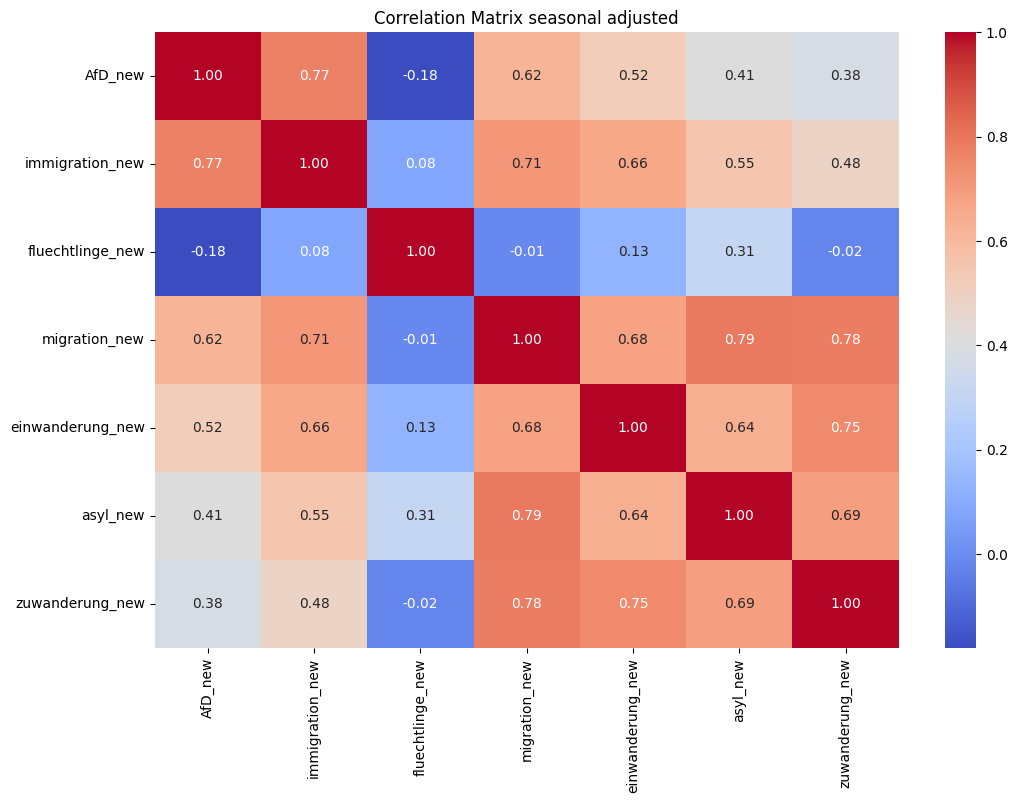

In [681]:
corr_matrix = pol_im_df[['AfD_new']+terms_new].corr()
corr_matrix = round(corr_matrix,2)
corr_matrix.to_csv('parties_terms_corr.csv', index=False) 

# Plot the correlation matrix
print('Correlation matrix\n')
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm')
plt.title("Correlation Matrix seasonal adjusted")
plt.show()

In [685]:
for i in terms_new:
    for z in terms_new:
        r, p = pearsonr(pol_im_df[i], pol_im_df[z])
        print(f"correlation of {i} with {z}: r = {r:.2f}, p = {p:.4f}")
    print("")

correlation of immigration_new with immigration_new: r = 1.00, p = 0.0000
correlation of immigration_new with fluechtlinge_new: r = 0.08, p = 0.1920
correlation of immigration_new with migration_new: r = 0.71, p = 0.0000
correlation of immigration_new with einwanderung_new: r = 0.66, p = 0.0000
correlation of immigration_new with asyl_new: r = 0.55, p = 0.0000
correlation of immigration_new with zuwanderung_new: r = 0.48, p = 0.0000

correlation of fluechtlinge_new with immigration_new: r = 0.08, p = 0.1920
correlation of fluechtlinge_new with fluechtlinge_new: r = 1.00, p = 0.0000
correlation of fluechtlinge_new with migration_new: r = -0.01, p = 0.8601
correlation of fluechtlinge_new with einwanderung_new: r = 0.13, p = 0.0471
correlation of fluechtlinge_new with asyl_new: r = 0.31, p = 0.0000
correlation of fluechtlinge_new with zuwanderung_new: r = -0.02, p = 0.8082

correlation of migration_new with immigration_new: r = 0.71, p = 0.0000
correlation of migration_new with fluechtlin

#### 3.3.2 OLS Regressions
We remember
- AfD polling results seasonal adjusted are not stationary (p-value >= 0.05).
- immigration_new is not stationary (p-value >= 0.05).
- fluechtlinge_new is stationary (p-value < 0.05).
- migration_new is stationary (p-value < 0.05).
- einwanderung_new is not stationary (p-value >= 0.05).
- asyl_new is stationary (p-value < 0.05).
- zuwanderung_new is stationary (p-value < 0.05).

In [605]:
# so we fit every regression for holisitic sake but only immigration and einwanderung are really valid
for i in ['immigration_new','einwanderung_new']:
    #define predictor and response variables
    y = pol_im_df['AfD_new']
    x = pol_im_df[i]

    #add constant to predictor variables
    x = sm.add_constant(x)

    #fit linear regression model
    model = sm.OLS(y, x).fit(cov_type='HAC', cov_kwds={'maxlags':2})
    result = adfuller(model.resid.dropna())

    print(f'Regression between AFD polling results and {i}')
    if model.pvalues[i]<0.05:
        print(f"Search indice significant! (p-value={model.pvalues[i]})")
        print(f'{round((model.rsquared*100),3)} % of variance are explained by search indice') 
    elif model.pvalues[i]>=0.05: 
        print(f"Search indice is not significant! (p-value={model.pvalues[i]})")
    if result[1] < 0.05: 
        print(f'Regression residuals between AFD polling results and {i} are stationary')
    elif result[1] > 0.05:
        print(f'Regression residuals between AFD polling results and {i} are NOT stationary')
    print("")

Regression between AFD polling results and immigration_new
Search indice significant! (p-value=4.548743891904403e-62)
58.987 % of variance are explained by search indice
Regression residuals between AFD polling results and immigration_new are NOT stationary

Regression between AFD polling results and einwanderung_new
Search indice significant! (p-value=1.0989655496126495e-11)
27.397 % of variance are explained by search indice
Regression residuals between AFD polling results and einwanderung_new are NOT stationary



Residuals are not stationary, therefore we have to differentiate both series to assess the real relationship. 

In [606]:
# residuals are not stationary so we re run with differentiated series again
for i in ['immigration_new', 'einwanderung_new']:

    tempo = pol_im_df[['AfD_new', i]].copy()
    tempo = tempo.diff().dropna()

    y = tempo['AfD_new']
    x = sm.add_constant(tempo[i])

    model = sm.OLS(y, x).fit(cov_type='HAC', cov_kwds={'maxlags': 2})

    result = adfuller(model.resid.dropna())

    print(f"Regression between AFD polling results and {i}")
    if model.pvalues[i] < 0.05:
        print(f"Search indice significant! (p-value={model.pvalues[i]})")
        print(f"{round(model.rsquared * 100, 3)} % of variance explained")
    elif model.pvalues[i]>=0.05:
        print(f"Search indice NOT significant (p-value={model.pvalues[i]})")
    if result[1] < 0.05: 
        print(f'Regression residuals between AFD polling results and {i} are stationary')
    elif result[1] > 0.05:
        print(f'Regression residuals between AFD polling results and {i} are NOT stationary')
    print("")


Regression between AFD polling results and immigration_new
Search indice NOT significant (p-value=0.754818550387031)
Regression residuals between AFD polling results and immigration_new are stationary

Regression between AFD polling results and einwanderung_new
Search indice NOT significant (p-value=0.7727591756443906)
Regression residuals between AFD polling results and einwanderung_new are stationary



In [607]:
independent = ['fluechtlinge_new', 'migration_new','asyl_new', 'zuwanderung_new' ]

for i in independent:
    tempo = pol_im_df[['AfD_new', i]].copy()
    tempo['AfD_new'] = tempo['AfD_new'].diff()       
    tempo = tempo.dropna()                       

    y = tempo['AfD_new']
    x = sm.add_constant(tempo[i])

    #fit linear regression model
    model = sm.OLS(y, x).fit(cov_type='HAC', cov_kwds={'maxlags':2})
    result = adfuller(model.resid.dropna())

    print(f'Regression between AFD polling and {i}')
    if model.pvalues[i]<0.05:
        print(f"Search indice significant! (p-value={model.pvalues[i]})")
        print(f'{round((model.rsquared*100),3)} % of variance are explained by search indice') 
    elif model.pvalues[i]>=0.05: 
        print(f"Search indice is not significant! (p-value={model.pvalues[i]})")
    if result[1] < 0.05: 
        print(f'Regression residuals between AFD polling and {i} are stationary')
    elif result[1] > 0.05:
        print(f'Regression residuals between AFD polling and {i} are NOT stationary')
    print("")

Regression between AFD polling and fluechtlinge_new
Search indice is not significant! (p-value=0.08125615549549725)
Regression residuals between AFD polling and fluechtlinge_new are stationary

Regression between AFD polling and migration_new
Search indice is not significant! (p-value=0.7198161822118205)
Regression residuals between AFD polling and migration_new are stationary

Regression between AFD polling and asyl_new
Search indice is not significant! (p-value=0.9857335871059457)
Regression residuals between AFD polling and asyl_new are stationary

Regression between AFD polling and zuwanderung_new
Search indice is not significant! (p-value=0.8367290146390955)
Regression residuals between AFD polling and zuwanderung_new are stationary



#### 3.3.3 Autoregressive models 
In the same vain as the first assignement we fit auoregressive models to the AfD polling series and valid search indices

In [608]:
from statsmodels.tsa.ar_model import AutoReg
for i in range(1,20):
    model = AutoReg(pol_im_df['AfD_new'], lags=i, missing='drop').fit()
    print(f"lag: {i} with a of BIC: {model.bic}")

lag: 1 with a of BIC: 480.7198902599535
lag: 2 with a of BIC: 475.25122728588906
lag: 3 with a of BIC: 476.7625755794839
lag: 4 with a of BIC: 480.755359794906
lag: 5 with a of BIC: 485.07216264429405
lag: 6 with a of BIC: 489.31054022223725
lag: 7 with a of BIC: 492.3450528095573
lag: 8 with a of BIC: 494.8243421461451
lag: 9 with a of BIC: 498.3907224987133
lag: 10 with a of BIC: 499.8938178344394
lag: 11 with a of BIC: 497.15954527626667
lag: 12 with a of BIC: 500.8862296262099
lag: 13 with a of BIC: 504.9701063385043
lag: 14 with a of BIC: 508.9612150009107
lag: 15 with a of BIC: 510.8260100642917
lag: 16 with a of BIC: 512.5604838054655
lag: 17 with a of BIC: 512.4560823446643
lag: 18 with a of BIC: 516.2549506467788
lag: 19 with a of BIC: 516.7659829414697


In [609]:
for i in range(1,20):
    model = AutoReg(pol_im_df['AfD_new'], lags=i, missing='drop', exog=pol_im_df[terms_new]).fit()
    print(f"lag: {i} with a of BIC: {model.bic}")

lag: 1 with a of BIC: 504.3297016344252
lag: 2 with a of BIC: 498.2052866881
lag: 3 with a of BIC: 500.222063193582
lag: 4 with a of BIC: 504.4073743908232
lag: 5 with a of BIC: 508.83168761086824
lag: 6 with a of BIC: 513.2405411736902
lag: 7 with a of BIC: 515.8877510022321
lag: 8 with a of BIC: 518.2567424080249
lag: 9 with a of BIC: 521.6424783662397
lag: 10 with a of BIC: 523.0365741506088
lag: 11 with a of BIC: 520.5095496206415
lag: 12 with a of BIC: 523.8536945753202
lag: 13 with a of BIC: 528.0757454760748
lag: 14 with a of BIC: 531.8621579560398
lag: 15 with a of BIC: 534.264962279916
lag: 16 with a of BIC: 535.5348621004757
lag: 17 with a of BIC: 535.0891757298732
lag: 18 with a of BIC: 538.4307102509086
lag: 19 with a of BIC: 538.0807556481933


In [721]:
autoreg = AutoReg(pol_im_df['AfD_new'], lags=2, missing='drop').fit()
combined_model = AutoReg(pol_im_df['AfD_new'], lags=0, missing='drop', exog=pol_im_df[['immigration_new','einwanderung_new']]).fit()
combined_lagged = AutoReg(pol_im_df['AfD_new'], lags=2, missing='drop', exog=pol_im_df[['immigration_new','einwanderung_new']]).fit()

print(f"Autoregressive model lag = 2 BIC:  {autoreg.bic}")
print(f"Autoregressive model (lag = 0) combined with immigration topic model BIC:  {combined_model.bic}")
print(f"Autoregressive model (lag = 2) combined with immigration topic model BIC: {combined_lagged.bic}")

Autoregressive model lag = 2 BIC:  475.25122728588906
Autoregressive model (lag = 0) combined with immigration topic model BIC:  1343.9123643248429
Autoregressive model (lag = 2) combined with immigration topic model BIC: 485.4251779828194


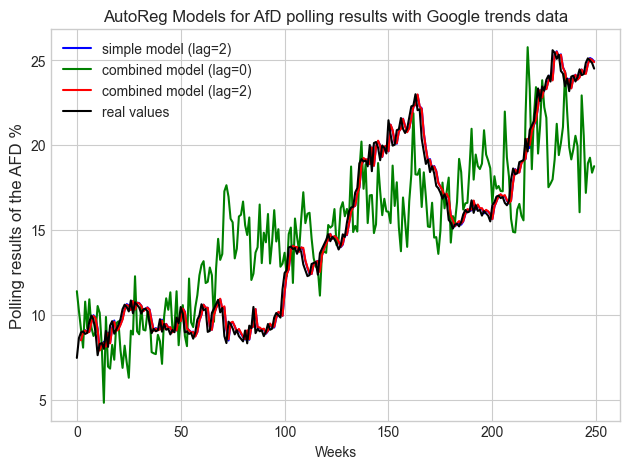

In [728]:
# Creating a line chart showing the three models plotted against the real value of AFD

plt.plot(autoreg.fittedvalues, label="simple model (lag=2)", color='blue')
plt.plot(combined_model.fittedvalues, label="combined model (lag=0)", color='green')
plt.plot(combined_lagged.fittedvalues, label="combined model (lag=2)", color='red')
plt.plot (pol_im_df['AfD_new'], label= "real values", color="black")

# Add labels and title
plt.title("AutoReg Models for AfD polling results with Google trends data")
plt.xlabel("Weeks")
plt.ylabel("Polling results of the AFD %", fontsize= 12 )
plt.legend()

# Show the plot with grid
plt.tight_layout()
plt.grid(True)
plt.show()

## 4. Analysis with monthly data to avoid synthetic data of interpolation

### 4.1 Seasonal adjustment on a monthly basis

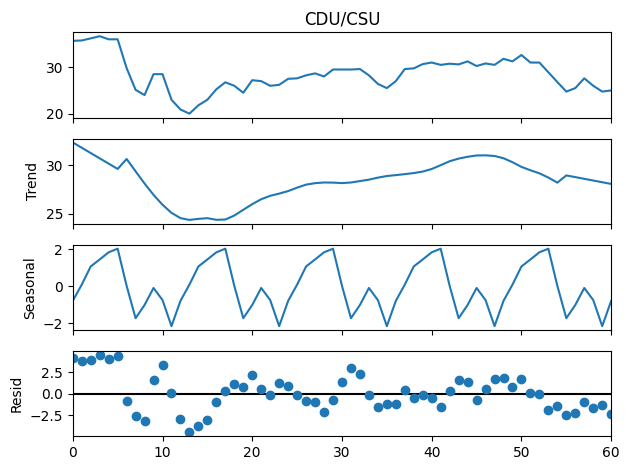

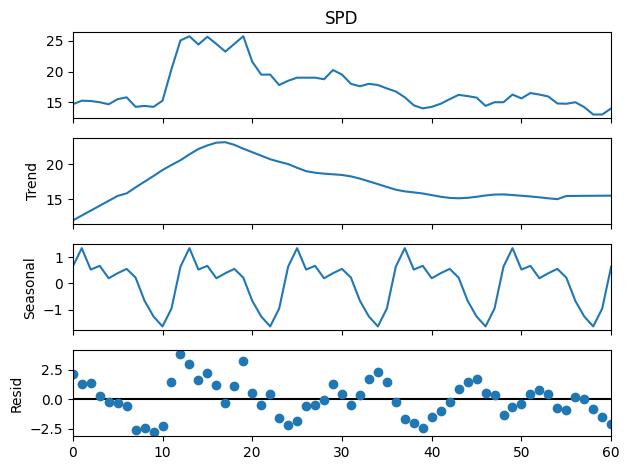

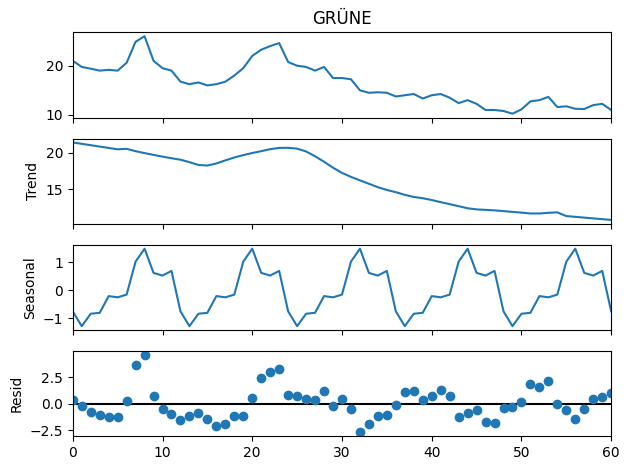

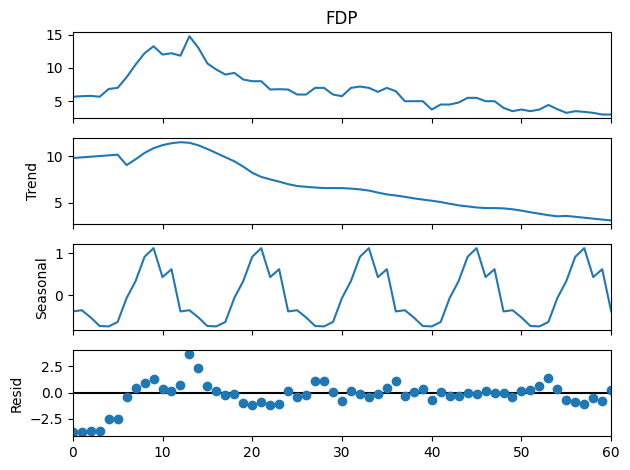

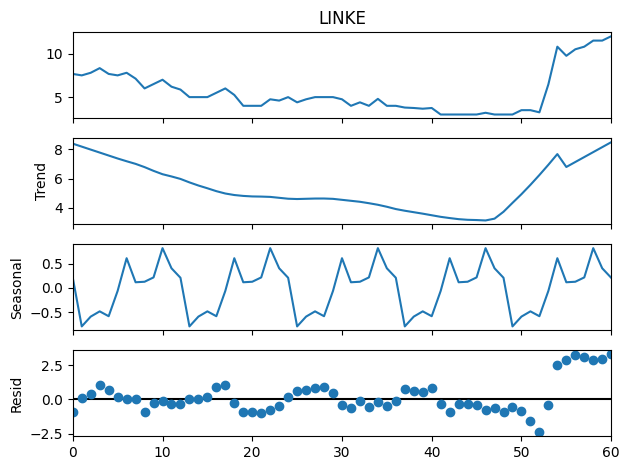

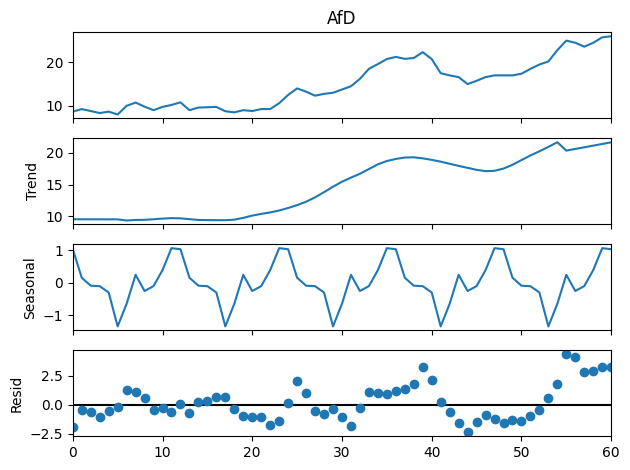

In [516]:
polling_monthly =polling_data.copy()
polling_monthly['month'] = polling_monthly.index.month
polling_monthly = polling_monthly.groupby(['year','month'])[parties+parties_new].mean().reset_index()

for i,z in zip(parties, parties_new):
    result = seasonal_decompose(polling_monthly[i], model='additive', extrapolate_trend='freq', period = 12)
    result.plot()
    polling_monthly[z] = polling_monthly[i] - result.seasonal

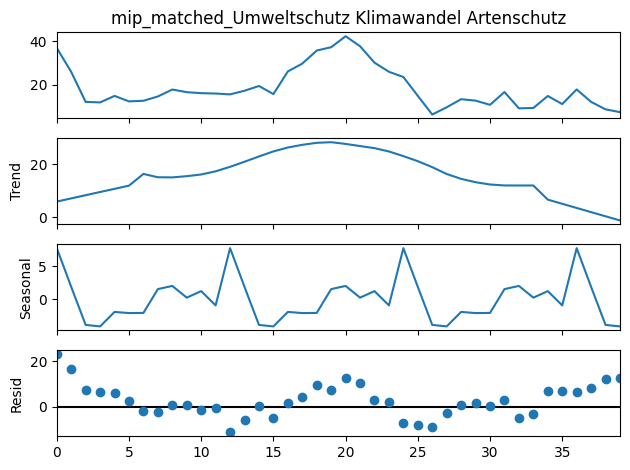

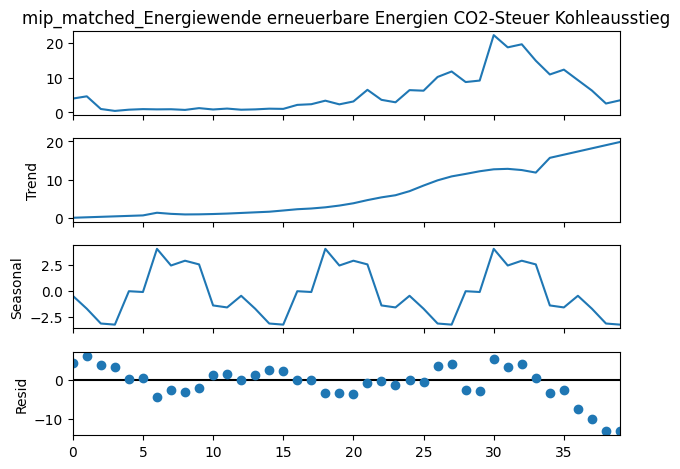

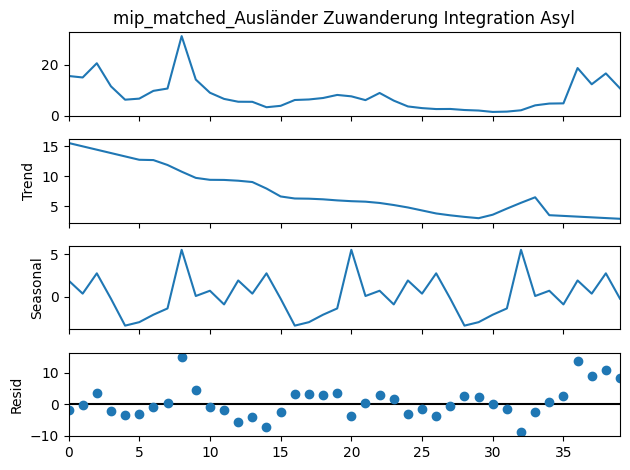

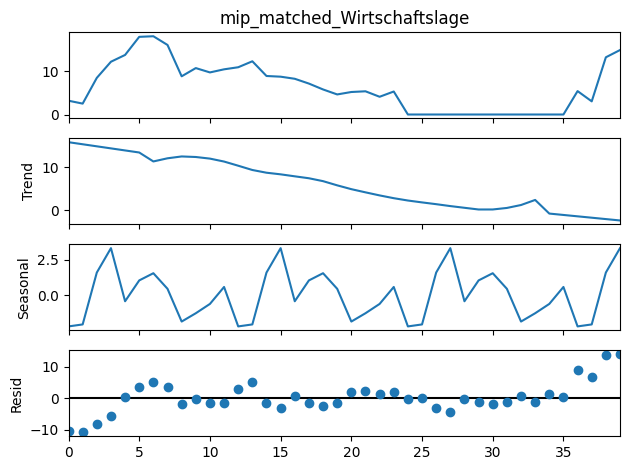

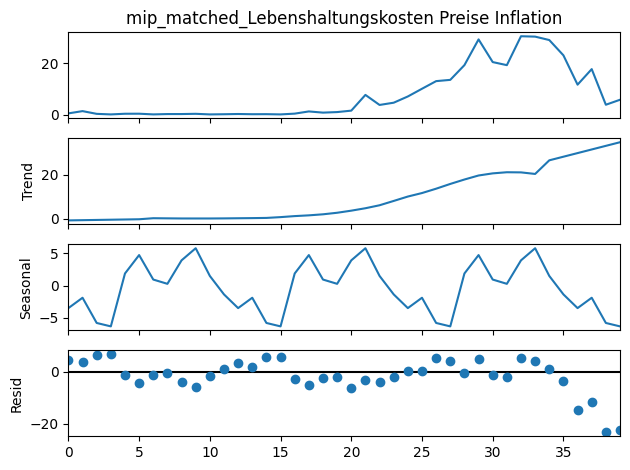

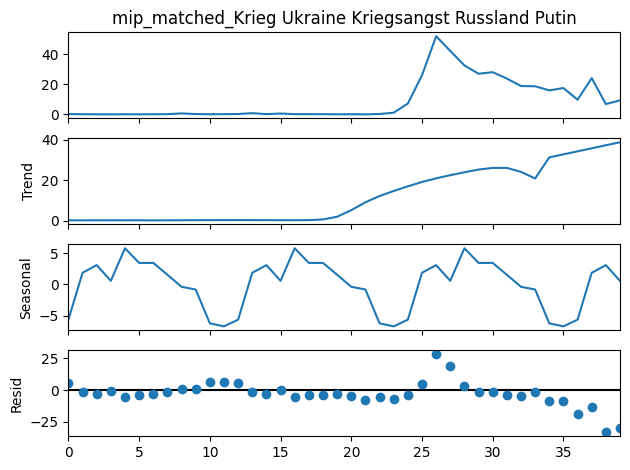

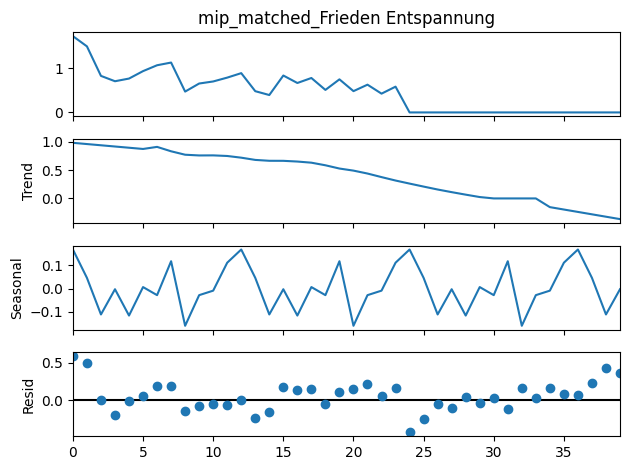

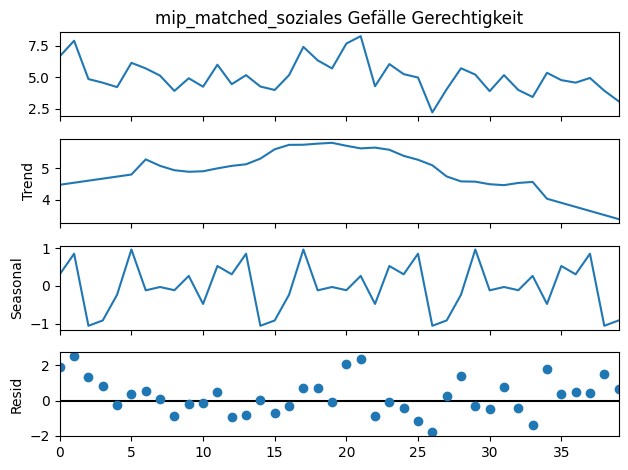

In [ ]:
# checking with monthly aka not interpolated data, because mip data had a lot of missing weeks
mip_monthly = mip_df_filtered.copy()
mip_monthly['date'] = pd.to_datetime(mip_monthly['year'].astype(str) + mip_monthly['week'].astype(str) + '1',format='%G%V%u')
mip_monthly['month'] = mip_monthly['date'].dt.month
mip_monthly = mip_monthly.set_index('date')

mip_monthly = mip_monthly.groupby(['year','month'])[matched_topics].mean().reset_index()

mip_columns_new = ['mip_climate_new','mip_energy_new','mip_immigration_new','mip_economy_new','mip_inflation_new',
                   'mip_war_new','mip_peace_new','mip_social_new']

for i,z in zip(matched_topics, mip_columns_new):
    result = seasonal_decompose(mip_monthly[i], model='additive', extrapolate_trend='freq', period=12)
    result.plot()
    mip_monthly[z] = mip_monthly[i] - result.seasonal


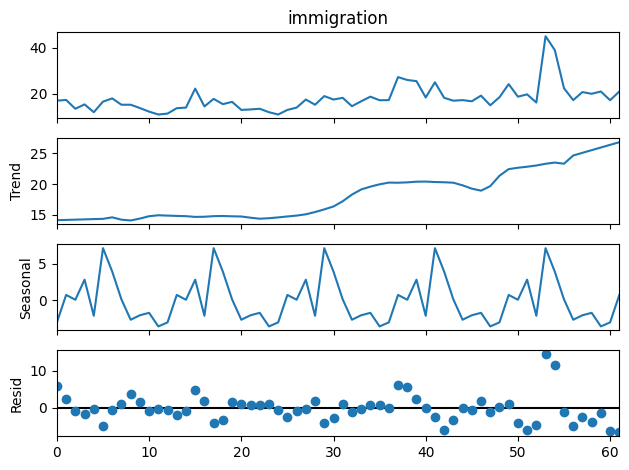

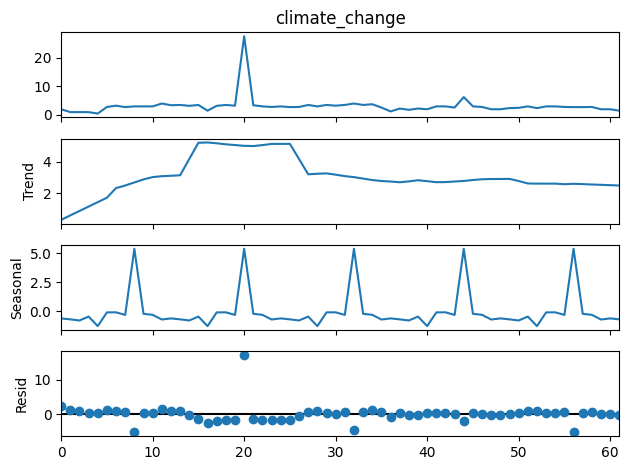

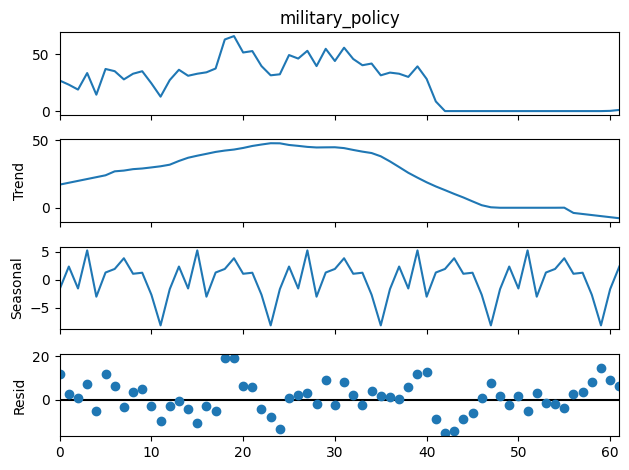

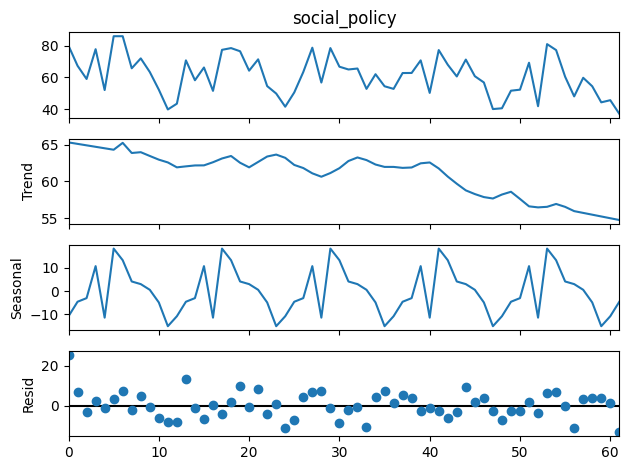

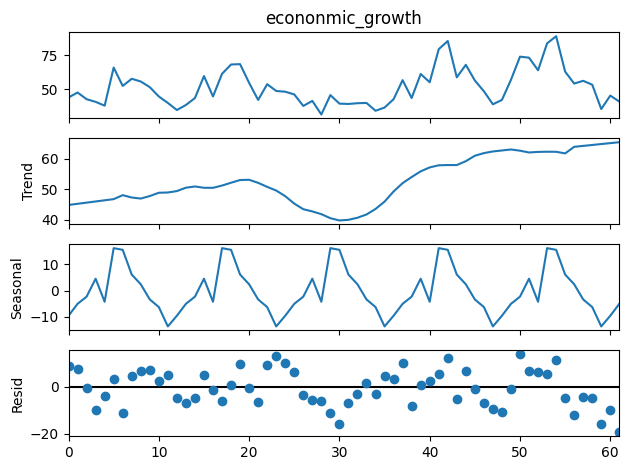

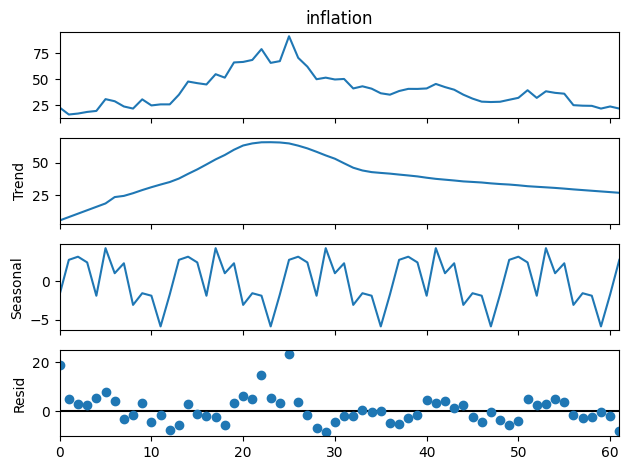

In [518]:
topics_monthly = topic_df.groupby(['year','month'])[columns].mean().reset_index()
for i,z in zip(columns, columns_new):
    result = seasonal_decompose(topics_monthly[i], model='additive', extrapolate_trend='freq', period=12)
    result.plot()
    topics_monthly[z] = topics_monthly[i] - result.seasonal

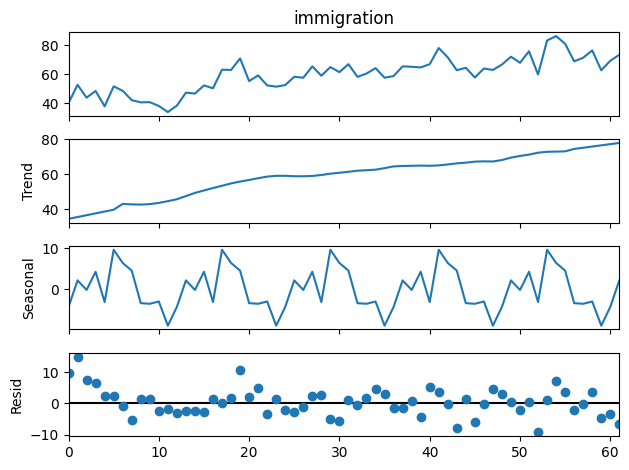

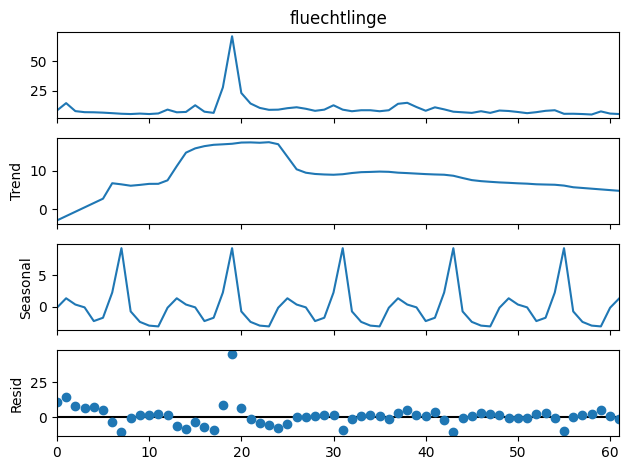

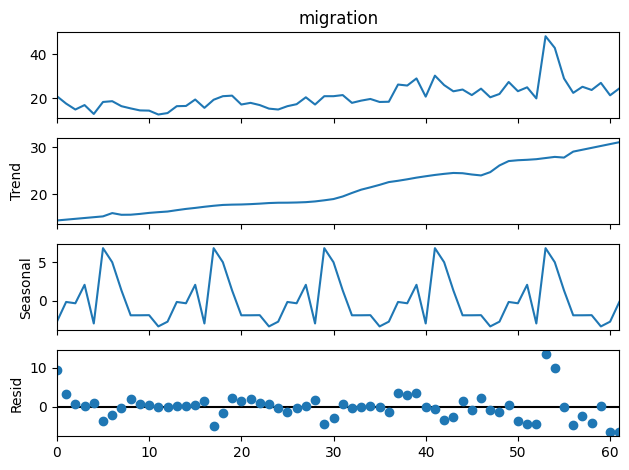

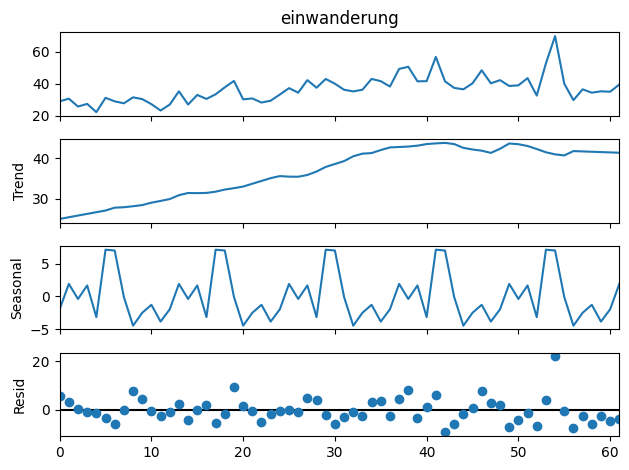

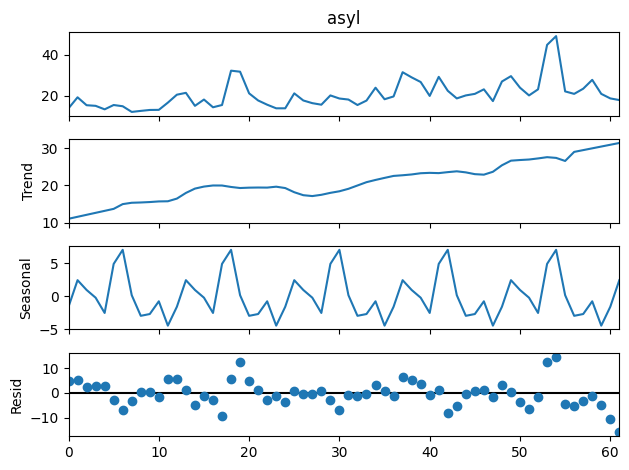

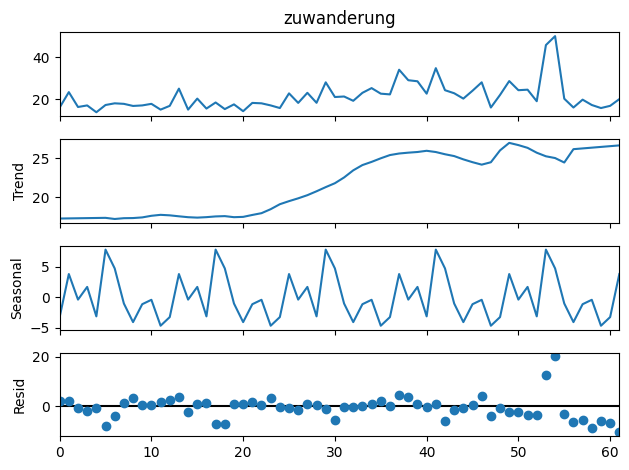

In [519]:
terms_monthly = term_df.groupby(['year','month'])[terms].mean().reset_index()
for i,z in zip(terms, terms_new):
    result = seasonal_decompose(terms_monthly[i], model='additive', extrapolate_trend='freq', period=12)
    result.plot()
    terms_monthly[z] = terms_monthly[i] - result.seasonal

### 4.2 Validation with monthly data

In [619]:
print("Stationarity results of MIP Questions")
for i in mip_columns_new:
    result = adfuller(mip_monthly[i].dropna())
    if result[1] < 0.05 : print(f"{i} is stationary (p-value < 0.05).")
    else:
        print(f"{i} is not stationary (p-value >= 0.05).")
print("")
print("Stationarity Results of Topic search indices")
for i in columns_new:
    result = adfuller(topics_monthly[i].dropna())
    if result[1] < 0.05 : print(f"{i} is stationary (p-value < 0.05).")
    else:
        print(f"{i} is not stationary (p-value >= 0.05).")
print("")
print("Stationarity results of immigration related search terms")
for i in terms_new:
    result = adfuller(terms_monthly[i].dropna())
    if result[1] < 0.05 : print(f"{i} is stationary (p-value < 0.05).")
    else:
        print(f"{i} is not stationary (p-value >= 0.05).")

Stationarity results of MIP Questions
mip_climate_new is not stationary (p-value >= 0.05).
mip_energy_new is not stationary (p-value >= 0.05).
mip_immigration_new is stationary (p-value < 0.05).
mip_economy_new is not stationary (p-value >= 0.05).
mip_inflation_new is not stationary (p-value >= 0.05).
mip_war_new is not stationary (p-value >= 0.05).
mip_peace_new is not stationary (p-value >= 0.05).
mip_social_new is not stationary (p-value >= 0.05).

Stationarity Results of Topic search indices
immigration_new is not stationary (p-value >= 0.05).
climate_change_new is stationary (p-value < 0.05).
military_policy_new is not stationary (p-value >= 0.05).
social_policy_new is stationary (p-value < 0.05).
econonmic_growth_new is stationary (p-value < 0.05).
inflation_new is not stationary (p-value >= 0.05).

Stationarity results of immigration related search terms
immigration_new is not stationary (p-value >= 0.05).
fluechtlinge_new is stationary (p-value < 0.05).
migration_new is not sta

Following combinations are valid according to Mellon (2014)
-	Immigration MIP and topic immigration but topic has to be differentiated
-	Topic Military policy and MIP war and peace but check residuals
-	Topic Inflation and MIP inflation but check residuals
-	All search terms for immigration but difference all non-stationary once beforehand ()

In [620]:
merge_df = pd.merge(mip_monthly, topics_monthly, on=['year','month'])
dependent = ['mip_peace_new', 'mip_war_new', 'mip_inflation_new']
independent = ['military_policy_new', 'military_policy_new', 'inflation_new']

for i,z in zip(dependent, independent):
    #define predictor and response variables
    y = merge_df[i]
    x = merge_df[z]

    #add constant to predictor variables
    x = sm.add_constant(x)

    #fit linear regression model
    model = sm.OLS(y, x).fit(cov_type='HAC', cov_kwds={'maxlags':2})
    result = adfuller(model.resid.dropna())

    print(f'Regression between {z} and {i}')
    if model.pvalues[z]<0.05:
        print(f"Search indice significant! (p-value={model.pvalues[z]})")
        print(f'{round((model.rsquared*100),3)} % of variance are explained by search indice') 
    elif model.pvalues[z]>=0.05: 
        print(f"Search indice is not significant! (p-value={model.pvalues[z]})")
    if result[1] < 0.05: 
        print(f'Regression residuals between {z} and {i} are stationary')
    elif result[1] > 0.05:
        print(f'Regression residuals between {z} and {i} are NOT stationary')
    print("")

Regression between military_policy_new and mip_peace_new
Search indice is not significant! (p-value=0.07633456788223023)
Regression residuals between military_policy_new and mip_peace_new are NOT stationary

Regression between military_policy_new and mip_war_new
Search indice significant! (p-value=0.0008754098868210046)
49.567 % of variance are explained by search indice
Regression residuals between military_policy_new and mip_war_new are NOT stationary

Regression between inflation_new and mip_inflation_new
Search indice significant! (p-value=1.0458981930328742e-34)
77.033 % of variance are explained by search indice
Regression residuals between inflation_new and mip_inflation_new are NOT stationary



In [621]:
# neeed to differentiate to meet matching sattionarity
for i in ['immigration_new']:
    tempo = merge_df[['mip_immigration_new', i]].copy()
    tempo[i] = tempo[i].diff()  
    tempo = tempo.dropna()

    y = tempo['mip_immigration_new']  
    x = sm.add_constant(tempo[i])    

    model = sm.OLS(y, x).fit(cov_type='HAC', cov_kwds={'maxlags':2})

    print(f'Regression between mip immigration question and {i}')
    if  model.pvalues[i] < 0.05:
        print(f"Search indice significant! (p-value={model.pvalues[i]})")
        print(f'{round((model.rsquared*100),3)} % of variance are explained by search indice') 
    else: 
        print(f"Search indice is not significant! (p-value={model.pvalues[i]})")
    print("")

Regression between mip immigration question and immigration_new
Search indice is not significant! (p-value=0.28415317697291964)



In [622]:
# OLS regression between search term indices and mip questions 
merge_df = pd.merge(mip_monthly, terms_monthly, on=['year','month'])

for i in ['fluechtlinge_new', 'zuwanderung_new']:
    #define predictor and response variables
    y = merge_df['mip_immigration_new']
    x = merge_df[i]

    #add constant to predictor variables
    x = sm.add_constant(x)

    #fit linear regression model
    model = sm.OLS(y, x).fit(cov_type='HAC', cov_kwds={'maxlags':2})

    print(f'Regression between mip immigration question and {i}')
    if  model.pvalues[i] < 0.05:
        print(f"Search indice significant! (p-value={model.pvalues[i]})")
        print(f'{round((model.rsquared*100),3)} % of variance are explained by search indice') 
    else: 
        print(f"Search indice is not significant! (p-value={model.pvalues[i]})")
    print("")

Regression between mip immigration question and fluechtlinge_new
Search indice is not significant! (p-value=0.17963405454504133)

Regression between mip immigration question and zuwanderung_new
Search indice significant! (p-value=0.01721413971480573)
5.478 % of variance are explained by search indice



In [623]:
for i in ['immigration_new', 'migration_new','einwanderung_new','asyl_new']:

    tempo = merge_df[['mip_immigration_new', i]].copy()
    tempo[i] = tempo[i].diff()
    tempo = tempo.dropna()
    y = tempo['mip_immigration_new']
    x = sm.add_constant(tempo[i])

    model = sm.OLS(y, x).fit(cov_type='HAC', cov_kwds={'maxlags':2})

    print(f'Regression between mip immigration question and {i}')
    if  model.pvalues[i] < 0.05:
        print(f"Search indice significant! (p-value={model.pvalues[i]})")
        print(f'{round((model.rsquared*100),3)} % of variance are explained by search indice') 
    else: 
        print(f"Search indice is not significant! (p-value={model.pvalues[i]})")
    print("")

Regression between mip immigration question and immigration_new
Search indice is not significant! (p-value=0.899832651217479)

Regression between mip immigration question and migration_new
Search indice is not significant! (p-value=0.2989390311196496)

Regression between mip immigration question and einwanderung_new
Search indice is not significant! (p-value=0.2146286015491412)

Regression between mip immigration question and asyl_new
Search indice is not significant! (p-value=0.8630930039023015)



### 4.3 MIP questions and Polling Data

In [678]:
pol_mip_monthly = pd.merge(polling_monthly,mip_monthly , on=['year','month'])
pol_mip_monthly = pol_mip_monthly[['year', 'month']+parties_new+mip_columns_new]
pol_mip_monthly.head()

,year,month,CDU/CSU_new,SPD_new,GRÜNE_new,FDP_new,LINKE_new,AfD_new,mip_climate_new,mip_energy_new,mip_immigration_new,mip_economy_new,mip_inflation_new,mip_war_new,mip_peace_new,mip_social_new
0,2020,9,36.455685,14.028381,21.759802,6.048947,7.458391,7.637718,15.635799,-2.219020,25.761174,10.743464,-3.723088,0.986114,0.633480,4.041609
1,2020,10,35.658483,13.907466,21.040735,6.103256,8.287820,9.098730,16.195129,-1.355726,14.153004,12.064297,-5.525810,1.009125,0.685471,4.666478
2,2020,11,35.123695,14.673638,20.245777,6.324802,8.386679,8.894273,14.742023,2.228720,8.346060,10.399163,-1.428619,6.271038,0.712941,4.740236
3,2020,12,35.211198,14.331893,19.811861,6.394681,8.812830,8.442732,16.740456,2.674133,7.540780,9.922763,1.520892,6.822956,0.680485,5.474923
4,2021,1,34.157035,14.471398,19.380028,7.570810,8.245647,8.969941,7.673965,1.225701,3.581153,13.188186,3.751673,5.841116,0.725584,4.154474


Correlation matrix



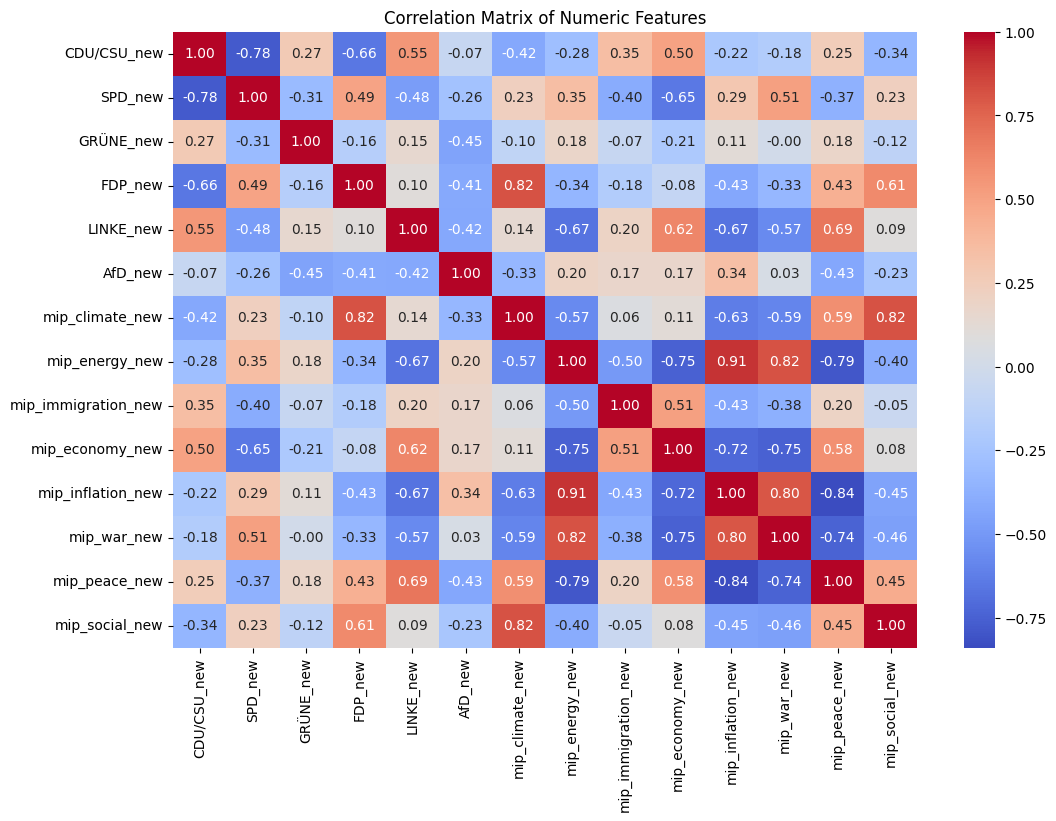

In [680]:
corr_matrix = pol_mip_monthly[parties_new+mip_columns_new].corr()
corr_matrix = round(corr_matrix,2)
corr_matrix.to_csv('parties_mip_monthly_corr.csv', index=False) 

print('Correlation matrix\n')
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm')
plt.title("Correlation Matrix of Numeric Features")
plt.show()

In [659]:
for i in mip_columns_new:
    print(f"Correlations of {i}")
    for z in parties_new:
        r, p = pearsonr(pol_mip_monthly[i], pol_mip_monthly[z])
        print(f"correlation of {i} with {z}: r = {r:.2f}, p = {p:.4f}")
    print("")

Correlations of mip_climate_new
correlation of mip_climate_new with CDU/CSU_new: r = -0.42, p = 0.0170
correlation of mip_climate_new with SPD_new: r = 0.23, p = 0.1993
correlation of mip_climate_new with GRÜNE_new: r = -0.10, p = 0.5694
correlation of mip_climate_new with FDP_new: r = 0.82, p = 0.0000
correlation of mip_climate_new with LINKE_new: r = 0.14, p = 0.4367
correlation of mip_climate_new with AfD_new: r = -0.33, p = 0.0635

Correlations of mip_energy_new
correlation of mip_energy_new with CDU/CSU_new: r = -0.28, p = 0.1274
correlation of mip_energy_new with SPD_new: r = 0.35, p = 0.0485
correlation of mip_energy_new with GRÜNE_new: r = 0.18, p = 0.3114
correlation of mip_energy_new with FDP_new: r = -0.34, p = 0.0563
correlation of mip_energy_new with LINKE_new: r = -0.67, p = 0.0000
correlation of mip_energy_new with AfD_new: r = 0.20, p = 0.2625

Correlations of mip_immigration_new
correlation of mip_immigration_new with CDU/CSU_new: r = 0.35, p = 0.0523
correlation of mi

In [649]:
print("Stationarity results of monthly polling data")
for i in parties_new:
    result = adfuller(pol_mip_monthly[i].dropna())
    if result[1] < 0.05 : print(f"{i} is stationary (p-value < 0.05).")
    else:
        print(f"{i} is not stationary (p-value >= 0.05).")

Stationarity results of monthly polling data
CDU/CSU_new is stationary (p-value < 0.05).
SPD_new is stationary (p-value < 0.05).
GRÜNE_new is stationary (p-value < 0.05).
FDP_new is not stationary (p-value >= 0.05).
LINKE_new is not stationary (p-value >= 0.05).
AfD_new is not stationary (p-value >= 0.05).


remember: 
Stationarity results of MIP Questions
- mip_climate_new is not stationary (p-value >= 0.05).
- mip_energy_new is not stationary (p-value >= 0.05).
- mip_immigration_new is stationary (p-value < 0.05).
- mip_economy_new is not stationary (p-value >= 0.05).
- mip_inflation_new is not stationary (p-value >= 0.05).
- mip_war_new is not stationary (p-value >= 0.05).
- mip_peace_new is not stationary (p-value >= 0.05).
- mip_social_new is not stationary (p-value >= 0.05).


therefore the following combinations are valid: 
- CDU with economy and inflaition differentiated
- SPD and social policy differentriated 
- Green and climate differentiated 
- FDP inflation and economy but check residuals
- LINKE and social but check residuals
- Afd differentiated and immigration normal

In [650]:
#we matched topics with parties based on recent studies and in line with issue ownership theory
dependent = ['LINKE_new','FDP_new', 'FDP_new']
independent = ['mip_social_new', 'mip_economy_new', 'mip_inflation_new']

for i,z in zip(dependent, independent):
    #define predictor and response variables
    y = pol_mip_monthly[i]
    x = pol_mip_monthly[z]

    #add constant to predictor variables
    x = sm.add_constant(x)

    #fit linear regression model
    model = sm.OLS(y, x).fit(cov_type='HAC', cov_kwds={'maxlags':2})
    result = adfuller(model.resid.dropna())

    print(f'Regression between {z} and {i}')
    if model.pvalues[z]<0.05:
        print(f"Search indice significant! (p-value={model.pvalues[z]})")
        print(f'{round((model.rsquared*100),3)} % of variance are explained by search indice') 
    elif model.pvalues[z]>=0.05: 
        print(f"Search indice is not significant! (p-value={model.pvalues[z]})")
    if result[1] < 0.05: 
        print(f'Regression residuals between {z} and {i} are stationary')
    elif result[1] > 0.05:
        print(f'Regression residuals between {z} and {i} are NOT stationary')
    print("")

Regression between mip_social_new and LINKE_new
Search indice is not significant! (p-value=0.41190075172123874)
Regression residuals between mip_social_new and LINKE_new are NOT stationary

Regression between mip_economy_new and FDP_new
Search indice is not significant! (p-value=0.6695470347750377)
Regression residuals between mip_economy_new and FDP_new are NOT stationary

Regression between mip_inflation_new and FDP_new
Search indice is not significant! (p-value=0.05698801596658684)
Regression residuals between mip_inflation_new and FDP_new are NOT stationary



In [663]:
# neeed to differentiate  search indices to meet matching sattionarity

dependent = ['CDU/CSU_new','CDU/CSU_new','SPD_new', 'GRÜNE_new']
independent = ['mip_economy_new', 'mip_inflation_new', 'mip_social_new','mip_climate_new' ]


for i,z in zip(dependent, independent):
    tempo = pol_mip_monthly[[i,z]].copy()
    tempo[z] = tempo[z].diff()       
    tempo = tempo.dropna()                       

    y = tempo[i]
    x = sm.add_constant(tempo[z])

    #fit linear regression model
    model = sm.OLS(y, x).fit(cov_type='HAC', cov_kwds={'maxlags':2})
    result = adfuller(model.resid.dropna())

    print(f'Regression between {z} and {i}')
    if model.pvalues[z]<0.05:
        print(f"Search indice significant! (p-value={model.pvalues[z]})")
        print(f'{round((model.rsquared*100),3)} % of variance are explained by search indice') 
    elif model.pvalues[z]>=0.05: 
        print(f"Search indice is not significant! (p-value={model.pvalues[z]})")
    if result[1] < 0.05: 
        print(f'Regression residuals between {z} and {i} are stationary')
    elif result[1] > 0.05:
        print(f'Regression residuals between {z} and {i} are NOT stationary')
    print("")

Regression between mip_economy_new and CDU/CSU_new
Search indice is not significant! (p-value=0.6149317740538984)
Regression residuals between mip_economy_new and CDU/CSU_new are stationary

Regression between mip_inflation_new and CDU/CSU_new
Search indice is not significant! (p-value=0.9877770495031847)
Regression residuals between mip_inflation_new and CDU/CSU_new are stationary

Regression between mip_social_new and SPD_new
Search indice is not significant! (p-value=0.6967877114088428)
Regression residuals between mip_social_new and SPD_new are stationary

Regression between mip_climate_new and GRÜNE_new
Search indice is not significant! (p-value=0.0894807524962645)
Regression residuals between mip_climate_new and GRÜNE_new are stationary



In [654]:
# neeed to differentiate  search indices to meet matching sattionarity

dependent = ['AfD_new']
independent = ['mip_immigration_new']


for i,z in zip(dependent, independent):
    tempo = pol_mip_monthly[[i,z]].copy()
    tempo[i] = tempo[i].diff()       
    tempo = tempo.dropna()                       

    y = tempo[i]
    x = sm.add_constant(tempo[z])

    #fit linear regression model
    model = sm.OLS(y, x).fit(cov_type='HAC', cov_kwds={'maxlags':2})
    result = adfuller(model.resid.dropna())

    print(f'Regression between {z} and {i}')
    if model.pvalues[z]<0.05:
        print(f"Search indice significant! (p-value={model.pvalues[z]})")
        print(f'{round((model.rsquared*100),3)} % of variance are explained by search indice') 
    elif model.pvalues[z]>=0.05: 
        print(f"Search indice is not significant! (p-value={model.pvalues[z]})")
    if result[1] < 0.05: 
        print(f'Regression residuals between {z} and {i} are stationary')
    elif result[1] > 0.05:
        print(f'Regression residuals between {z} and {i} are NOT stationary')
    print("")

Regression between mip_immigration_new and AfD_new
Search indice is not significant! (p-value=0.4887041182846461)
Regression residuals between mip_immigration_new and AfD_new are NOT stationary



### 4.4 Search indices and polling data

In [500]:
pol_topic_monthly = pd.merge(polling_monthly,topics_monthly , on=['year','month'])
pol_topic_monthly = pol_topic_monthly[['year', 'month']+parties_new+columns_new]
pol_topic_monthly.head()

,year,month,CDU/CSU_new,SPD_new,GRÜNE_new,FDP_new,LINKE_new,AfD_new,immigration_new,climate_change_new,military_policy_new,social_policy_new,econonmic_growth_new,inflation_new
0,2020,9,36.680283,14.273509,21.772782,6.333019,7.739886,7.916568,16.572672,1.679767,20.964543,71.910022,52.747282,13.580736
1,2020,10,36.027190,13.871691,21.217235,6.346570,8.364245,8.942861,13.397356,1.775929,20.547513,62.023262,45.087038,14.090710
2,2020,11,34.973555,14.628029,19.852178,6.625693,8.485544,8.981556,12.550760,1.438335,28.345284,67.122839,36.279389,16.380757
3,2020,12,35.422003,14.280199,19.805872,6.579816,8.519344,8.328584,14.092080,1.761157,17.513889,63.380332,42.286323,21.630388
4,2021,1,34.282952,14.707370,19.626231,7.529772,8.553143,9.175612,9.438817,2.879395,35.899577,67.815742,49.807007,26.737102


Correlation matrix



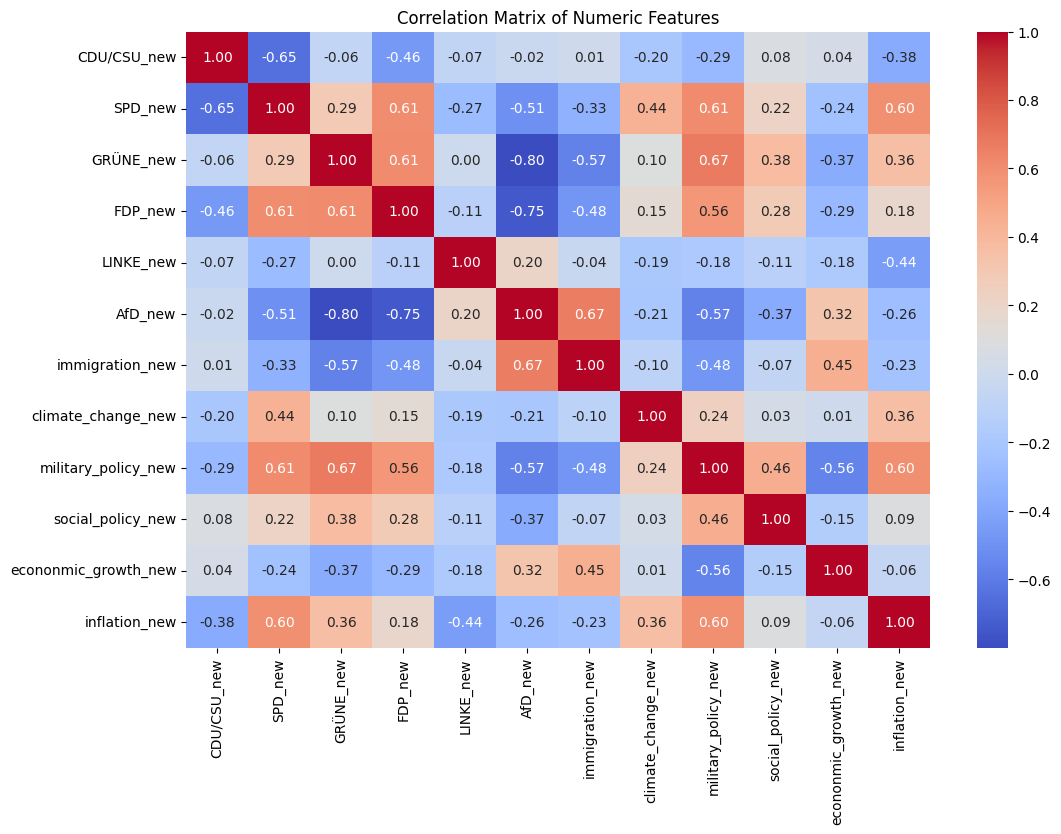

In [522]:
corr_matrix = pol_topic_monthly[parties_new+columns_new].corr()

print('Correlation matrix\n')
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm')
plt.title("Correlation Matrix of Numeric Features")
plt.show()

In [ ]:
#we matched topics with parties based on recent studies and in line with issue ownership theory
dependent = ['AfD_new','GRÜNE_new','LINKE_new','SPD_new','FDP_new', 'FDP_new','CDU/CSU_new', 'CDU/CSU_new' ]
independent = ['immigration_new','climate_change_new', 'social_policy_new','social_policy_new', 'econonmic_growth_new', 'inflation_new', 'econonmic_growth_new', 'inflation_new' ]

for i,z in zip(dependent, independent):
    #define predictor and response variables
    y = pol_topic_monthly[i]
    x = pol_topic_monthly[z]

    #add constant to predictor variables
    x = sm.add_constant(x)

    #fit linear regression model
    #account for autocorrelation with Newey West standard error
    model = sm.OLS(y, x).fit(cov_type='HAC', cov_kwds={'maxlags':2}) 

    print(f'Regression between {z} and {i}')
    if model.pvalues[z]<0.05:
        print(f"Search indice significant! (p-value={model.pvalues[z]})")
        print(f'{round((model.rsquared*100),3)} % of variance are explained by search indice') 
    else: 
        print(f"Search indice is not significant! (p-value={model.pvalues[z]})")
    print("")

Regression between immigration_new and AfD_new
Search indice significant! (p-value=7.920477959945659e-05)
44.795 % of variance are explained by search indice

Regression between climate_change_new and GRÜNE_new
Search indice is not significant! (p-value=0.25847131395484746)

Regression between social_policy_new and LINKE_new
Search indice is not significant! (p-value=0.5626635625500989)

Regression between social_policy_new and SPD_new
Search indice is not significant! (p-value=0.07471557035791838)

Regression between econonmic_growth_new and FDP_new
Search indice significant! (p-value=0.004119485967830825)
8.37 % of variance are explained by search indice

Regression between inflation_new and FDP_new
Search indice is not significant! (p-value=0.1845175170976231)

Regression between econonmic_growth_new and CDU/CSU_new
Search indice is not significant! (p-value=0.7542014499941875)

Regression between inflation_new and CDU/CSU_new
Search indice significant! (p-value=0.027771881342292172

### 4.6 Immigration related terms and AfD polling

In [510]:
pol_terms_monthly = pd.merge(polling_monthly,terms_monthly , on=['year','month'])
pol_terms_monthly = pol_terms_monthly[['year', 'month', 'AfD', 'AfD_new']+terms_new]
pol_terms_monthly.head()

,year,month,AfD,AfD_new,immigration_new,fluechtlinge_new,migration_new,einwanderung_new,asyl_new,zuwanderung_new
0,2020,9,9.0,7.916568,50.557720,12.976976,17.833303,28.760932,16.917591,19.505266
1,2020,10,9.0,8.942861,43.968835,7.128275,15.338743,26.140244,14.569059,16.632278
2,2020,11,9.0,8.981556,44.173257,6.673257,14.930963,25.728695,15.440543,15.292516
3,2020,12,8.0,8.328584,40.931844,8.732821,15.972349,25.411313,16.054526,16.894420
4,2021,1,9.0,9.175612,42.004599,7.910303,11.553735,24.073097,10.718093,9.349658


Correlation matrix



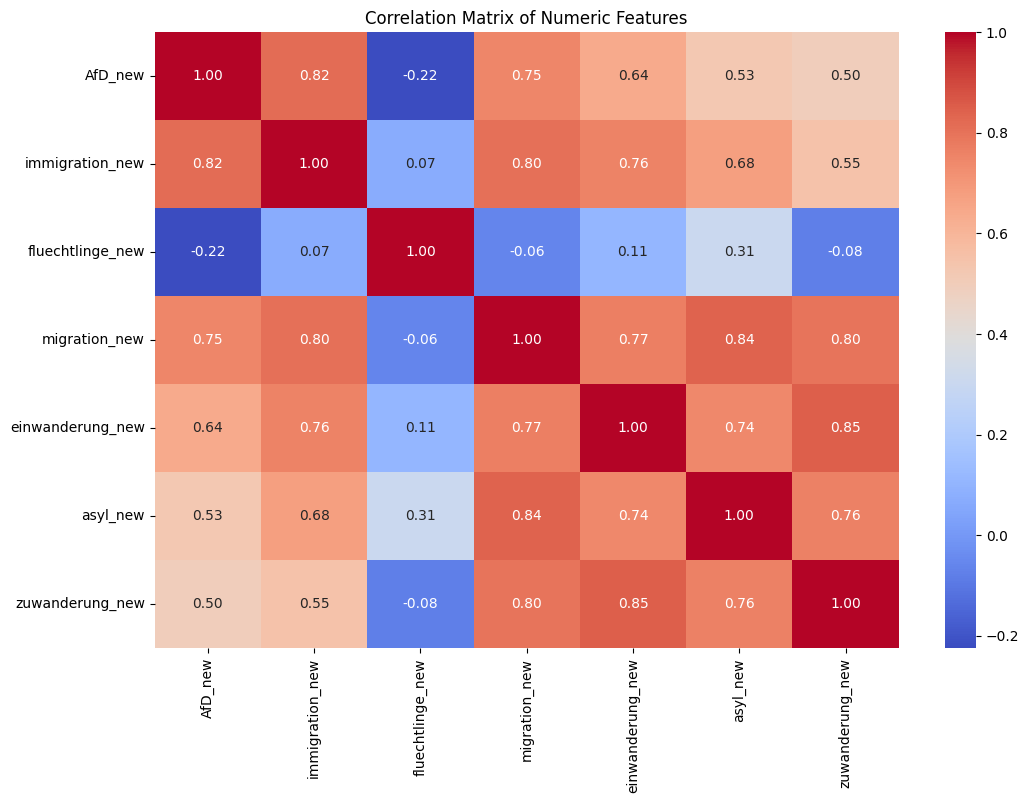

In [523]:
corr_matrix = pol_terms_monthly[['AfD_new']+terms_new].corr()

print('Correlation matrix\n')
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm')
plt.title("Correlation Matrix of Numeric Features")
plt.show()

In [552]:
# so we fit every regression for holisitic sake but only immigration and einwanderung are really valid
for i in terms_new:
    #define predictor and response variables
    y = pol_terms_monthly['AfD_new']
    x = pol_terms_monthly[i]

    #add constant to predictor variables
    x = sm.add_constant(x)

    #fit linear regression model
    model = sm.OLS(y, x).fit(cov_type='HAC', cov_kwds={'maxlags':2})

    print(f'Regression between seasonal adjusted AfD polling results and search term "{i}"')
    if  model.pvalues[i] < 0.05:
        print(f"Search indice significant! (p-value={model.pvalues[i]})")
        print(f'{round((model.rsquared*100),3)} % of variance are explained by search indice') 
    else: 
        print(f"Search indice is not significant! (p-value={model.pvalues[i]})")
    print("")

Regression between seasonal adjusted AfD polling results and search term "immigration_new"
Search indice significant! (p-value=7.913493925123087e-21)
66.772 % of variance are explained by search indice

Regression between seasonal adjusted AfD polling results and search term "fluechtlinge_new"
Search indice significant! (p-value=0.012766045729533616)
5.057 % of variance are explained by search indice

Regression between seasonal adjusted AfD polling results and search term "migration_new"
Search indice significant! (p-value=6.112786726888812e-06)
56.184 % of variance are explained by search indice

Regression between seasonal adjusted AfD polling results and search term "einwanderung_new"
Search indice significant! (p-value=1.483457088162317e-15)
40.875 % of variance are explained by search indice

Regression between seasonal adjusted AfD polling results and search term "asyl_new"
Search indice significant! (p-value=1.9882476910688784e-05)
27.598 % of variance are explained by search i